
# Intel Image Classification Using CNNs and Transfer Learning

## 1. Project Objective

The objective of this project is to build and evaluate image classification models using Convolutional Neural Networks (CNNs) and Transfer Learning.

The dataset contains six image classes:
- Buildings
- Forest
- Glacier
- Mountain
- Sea
- Street

This project includes dataset exploration, image preprocessing, data augmentation, CNN model development, ResNet-18 transfer learning, model evaluation, and prediction on new images.


In [1]:

from pathlib import Path
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("Basic libraries imported successfully!")


Basic libraries imported successfully!


In [2]:

# Define the project and dataset paths

PROJECT_DIR = Path(r"D:\SS\Jupyter_ML\Intel_Image_Classification")
DATA_DIR = PROJECT_DIR / "archive"

TRAIN_DIR = DATA_DIR / "seg_train"
TEST_DIR = DATA_DIR / "seg_test"
PRED_DIR = DATA_DIR / "seg_pred"

# Check whether each folder exists

print("Project folder exists:", PROJECT_DIR.exists())
print("Dataset folder exists:", DATA_DIR.exists())
print("Training folder exists:", TRAIN_DIR.exists())
print("Testing folder exists:", TEST_DIR.exists())
print("Prediction folder exists:", PRED_DIR.exists())


Project folder exists: True
Dataset folder exists: True
Training folder exists: True
Testing folder exists: True
Prediction folder exists: True


In [5]:

# Correct paths to the actual image class folders

TRAIN_DIR = DATA_DIR / "seg_train" / "seg_train"
TEST_DIR = DATA_DIR / "seg_test" / "seg_test"
PRED_DIR = DATA_DIR / "seg_pred"

# Verify the paths

print("Training classes:", sorted(
    folder.name for folder in TRAIN_DIR.iterdir() if folder.is_dir()
))

print("\nTesting classes:", sorted(
    folder.name for folder in TEST_DIR.iterdir() if folder.is_dir()
))

print("\nTraining folder exists:", TRAIN_DIR.exists())
print("Testing folder exists:", TEST_DIR.exists())
print("Prediction folder exists:", PRED_DIR.exists())


Training classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Testing classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Training folder exists: True
Testing folder exists: True
Prediction folder exists: True


In [7]:

# Reset the correct dataset paths

PROJECT_DIR = Path(r"D:\SS\Jupyter_ML\Intel_Image_Classification")
DATA_DIR = PROJECT_DIR / "archive"

TRAIN_DIR = DATA_DIR / "seg_train" / "seg_train"
TEST_DIR = DATA_DIR / "seg_test" / "seg_test"
PRED_DIR = DATA_DIR / "seg_pred"

# Re-create class lists from the corrected paths

train_classes = sorted(
    folder.name for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
)

test_classes = sorted(
    folder.name for folder in TEST_DIR.iterdir()
    if folder.is_dir()
)

print("Training path:", TRAIN_DIR)
print("Training classes:", train_classes)
print("Testing path:", TEST_DIR)
print("Testing classes:", test_classes)


Training path: D:\SS\Jupyter_ML\Intel_Image_Classification\archive\seg_train\seg_train
Training classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Testing path: D:\SS\Jupyter_ML\Intel_Image_Classification\archive\seg_test\seg_test
Testing classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [8]:

# Count images in each training and testing class

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

train_counts = {}
test_counts = {}

for class_name in train_classes:
    class_folder = TRAIN_DIR / class_name
    train_counts[class_name] = sum(
        1 for file in class_folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    )

for class_name in test_classes:
    class_folder = TEST_DIR / class_name
    test_counts[class_name] = sum(
        1 for file in class_folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    )

# Create a summary table

class_distribution = pd.DataFrame({
    "Class": train_classes,
    "Training Images": [train_counts[c] for c in train_classes],
    "Testing Images": [test_counts[c] for c in test_classes]
})

display(class_distribution)

print("Total training images:", sum(train_counts.values()))
print("Total testing images:", sum(test_counts.values()))


,Class,Training Images,Testing Images
0,buildings,2191,437
1,forest,2271,474
2,glacier,2404,553
3,mountain,2512,525
4,sea,2274,510
5,street,2382,501


Total training images: 14034
Total testing images: 3000


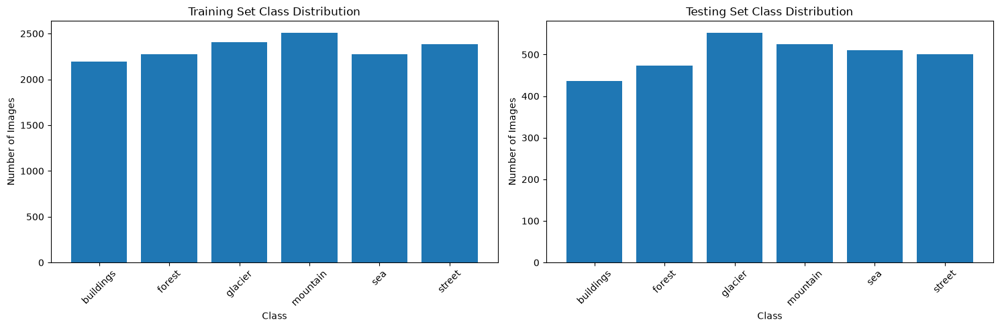

In [9]:

# Visualize class distribution

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(train_counts.keys(), train_counts.values())
axes[0].set_title("Training Set Class Distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Images")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(test_counts.keys(), test_counts.values())
axes[1].set_title("Testing Set Class Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of Images")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()



### Class Distribution — Observations

- The training dataset contains 14,034 images across six classes.
- The testing dataset contains 3,000 images across the same six classes.
- In the training dataset, `mountain` has the highest number of images (2,512), while `buildings` has the lowest (2,191).
- In the testing dataset, `glacier` has the highest number of images (553), while `buildings` has the lowest (437).
- The class distribution is relatively balanced, although the number of images differs slightly between classes.
- Separate training and testing datasets are available for model development and evaluation.


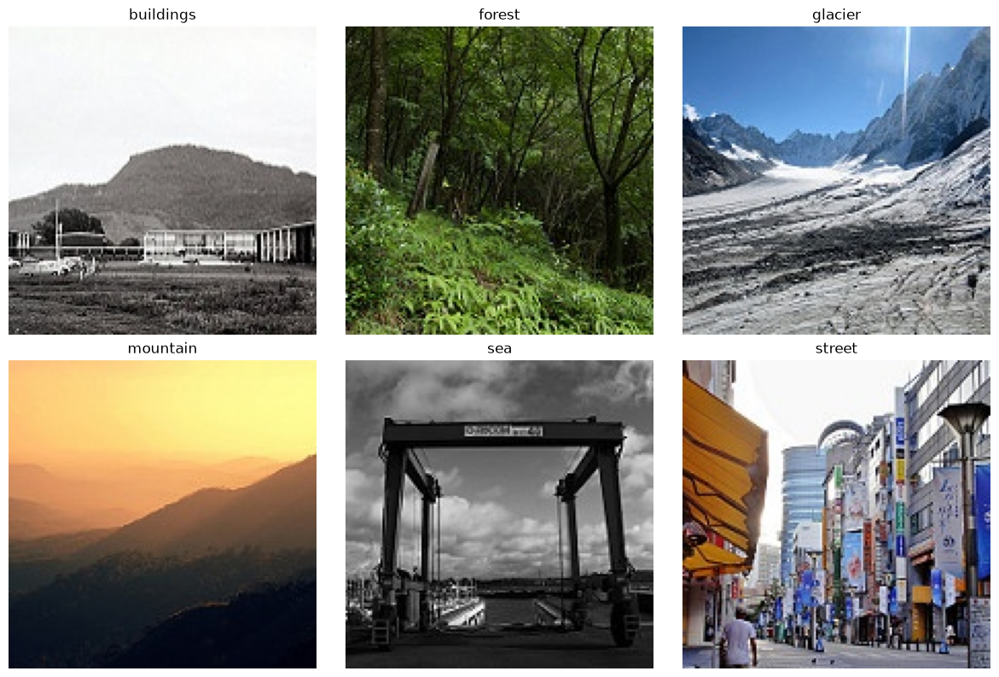

In [10]:

# Display one sample image from each class

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, class_name in zip(axes.flat, train_classes):
    class_folder = TRAIN_DIR / class_name

    image_files = sorted(
        file for file in class_folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    )

    image_path = image_files[0]

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [11]:

# Inspect image dimensions, formats, and corrupted files

from collections import Counter

image_dimensions = Counter()
image_formats = Counter()
corrupted_images = []
total_checked = 0

for class_name in train_classes:
    class_folder = TRAIN_DIR / class_name

    for image_path in class_folder.iterdir():
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in image_extensions:
            continue

        total_checked += 1

        try:
            with Image.open(image_path) as img:
                image_dimensions[img.size] += 1
                image_formats[img.format] += 1
                img.verify()

        except Exception:
            corrupted_images.append(str(image_path))

print("Total training images checked:", total_checked)
print("\nImage dimensions:")
for dimension, count in image_dimensions.most_common():
    print(f"{dimension}: {count} images")

print("\nImage formats:")
for image_format, count in image_formats.items():
    print(f"{image_format}: {count} images")

print("\nCorrupted images found:", len(corrupted_images))


Total training images checked: 14034

Image dimensions:
(150, 150): 13986 images
(150, 113): 7 images
(150, 135): 3 images
(150, 111): 3 images
(150, 108): 2 images
(150, 136): 2 images
(150, 143): 2 images
(150, 146): 2 images
(150, 134): 2 images
(150, 142): 2 images
(150, 123): 2 images
(150, 144): 2 images
(150, 124): 1 images
(150, 133): 1 images
(150, 115): 1 images
(150, 110): 1 images
(150, 105): 1 images
(150, 120): 1 images
(150, 149): 1 images
(150, 119): 1 images
(150, 102): 1 images
(150, 76): 1 images
(150, 97): 1 images
(150, 103): 1 images
(150, 100): 1 images
(150, 141): 1 images
(150, 145): 1 images
(150, 81): 1 images
(150, 147): 1 images
(150, 131): 1 images
(150, 140): 1 images

Image formats:
JPEG: 14034 images

Corrupted images found: 0



### Image Quality and Format Inspection

- Total training images inspected: 14,034.
- All inspected images are in JPEG format.
- 13,986 images have dimensions of 150 × 150 pixels.
- The remaining 48 images have different heights, so image resizing will be required to ensure consistent input dimensions.
- No corrupted images were detected in the training dataset.
- Images will be resized to a consistent input size during preprocessing.


In [12]:

# Check image dimensions, formats, and corruption in the test dataset

test_dimensions = Counter()
test_formats = Counter()
test_corrupted_images = []
test_total_checked = 0

for class_name in test_classes:
    class_folder = TEST_DIR / class_name

    for image_path in class_folder.iterdir():
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in image_extensions:
            continue

        test_total_checked += 1

        try:
            with Image.open(image_path) as img:
                test_dimensions[img.size] += 1
                test_formats[img.format] += 1
                img.verify()

        except Exception:
            test_corrupted_images.append(str(image_path))

print("Total test images checked:", test_total_checked)
print("\nTest image dimensions:")
for dimension, count in test_dimensions.most_common():
    print(f"{dimension}: {count} images")

print("\nTest image formats:", dict(test_formats))
print("Corrupted test images:", len(test_corrupted_images))


Total test images checked: 3000

Test image dimensions:
(150, 150): 2993 images
(150, 141): 1 images
(150, 110): 1 images
(150, 76): 1 images
(150, 149): 1 images
(150, 72): 1 images
(150, 131): 1 images
(150, 81): 1 images

Test image formats: {'JPEG': 3000}
Corrupted test images: 0



### Test Dataset Quality Inspection

- Total test images inspected: 3,000.
- All test images are in JPEG format.
- 2,993 images have dimensions of 150 × 150 pixels.
- The remaining 7 images have different heights.
- No corrupted images were detected in the test dataset.
- All images will be resized consistently during preprocessing.
- The test dataset will be kept separate from training and validation during model development and hyperparameter tuning.


In [13]:

import torch
import torchvision
from torchvision import transforms

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
CUDA available: True


In [14]:

from torchvision.models import ResNet18_Weights

# Input size for our CNN built from scratch
CNN_IMAGE_SIZE = 224

# Preprocessing for the CNN built from scratch
train_transform = transforms.Compose([
    transforms.Resize((CNN_IMAGE_SIZE, CNN_IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Deterministic preprocessing for validation and testing
eval_transform = transforms.Compose([
    transforms.Resize((CNN_IMAGE_SIZE, CNN_IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Official preprocessing for pretrained ResNet-18 weights
resnet_weights = ResNet18_Weights.DEFAULT
resnet_transform = resnet_weights.transforms()

print("CNN training transform created.")
print("CNN evaluation transform created.")
print("ResNet-18 official transform created.")
print("\nResNet-18 expected input size:", resnet_transform.crop_size)


CNN training transform created.
CNN evaluation transform created.
ResNet-18 official transform created.

ResNet-18 expected input size: [224]


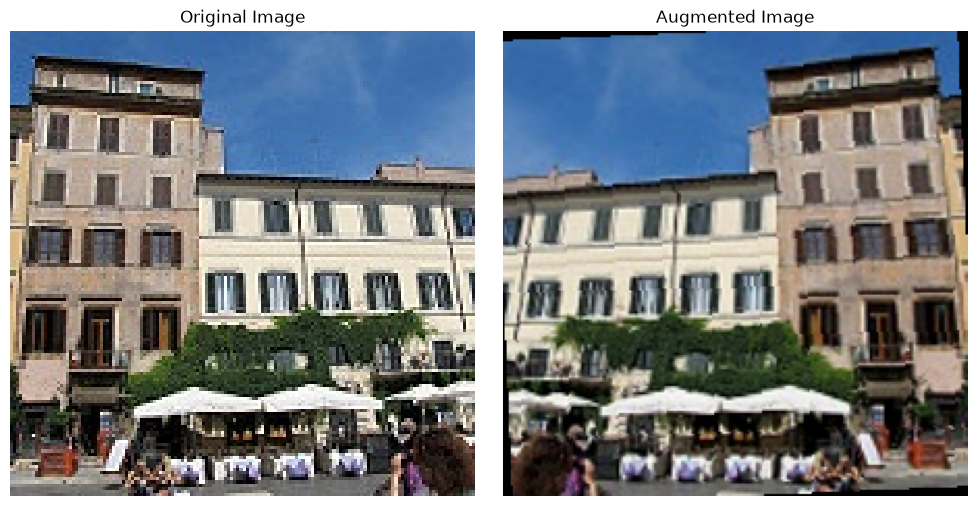

In [15]:
import matplotlib.pyplot as plt
from PIL import Image
import random

# Select one sample image from the training dataset
sample_class = "buildings"
sample_path = random.choice(list((TRAIN_DIR / sample_class).glob("*.jpg")))

# Load original image
original_image = Image.open(sample_path).convert("RGB")

# Apply random augmentation (without normalization for visualization)
augmentation_preview_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    )
])

augmented_image = augmentation_preview_transform(original_image)

# Display original and augmented images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image)
plt.title("Augmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Load one image
sample_image = Image.open(sample_path).convert("RGB")

# Apply training preprocessing
image_tensor = train_transform(sample_image)

print("Image tensor shape:", image_tensor.shape)
print("Tensor data type:", image_tensor.dtype)
print("Minimum normalized value:", image_tensor.min().item())
print("Maximum normalized value:", image_tensor.max().item())

Image tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32
Minimum normalized value: -2.1179039478302
Maximum normalized value: 2.640000104904175


In [17]:
from torchvision import datasets
from torch.utils.data import random_split, DataLoader
import torch

# Reproducible split
SEED = 42

# Load the original training dataset without transforms
full_train_dataset = datasets.ImageFolder(
    root=str(TRAIN_DIR),
    transform=None
)

# Check class names and class-to-index mapping
class_names = full_train_dataset.classes
class_to_idx = full_train_dataset.class_to_idx

print("Class names:", class_names)
print("Class-to-index mapping:", class_to_idx)
print("Total original training images:", len(full_train_dataset))

Class names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Class-to-index mapping: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
Total original training images: 14034


In [18]:
# Calculate training and validation sizes
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

# Split the dataset reproducibly
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Total images:", len(train_dataset) + len(val_dataset))

Training images: 11227
Validation images: 2807
Total images: 14034


In [19]:
from copy import copy

# Create separate dataset objects
train_base = copy(full_train_dataset)
val_base = copy(full_train_dataset)

# Apply different transformations
train_base.transform = train_transform
val_base.transform = eval_transform

# Attach the correct dataset to each split
train_dataset.dataset = train_base
val_dataset.dataset = val_base

print("Training transform:", train_dataset.dataset.transform)
print("\nValidation transform:", val_dataset.dataset.transform)

Training transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [20]:
# Batch size
BATCH_SIZE = 32

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch size:", BATCH_SIZE)

Training batches: 351
Validation batches: 88
Batch size: 32


In [21]:
# Get one batch from the training DataLoader
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("\nFirst 10 labels:", labels[:10].tolist())
print("Corresponding class names:",
      [class_names[label] for label in labels[:10].tolist()])

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64

First 10 labels: [1, 4, 2, 5, 5, 0, 4, 0, 4, 4]
Corresponding class names: ['forest', 'sea', 'glacier', 'street', 'street', 'buildings', 'sea', 'buildings', 'sea', 'sea']


## 4. Model 1 — Build a CNN From Scratch

In this section, we will build a Convolutional Neural Network (CNN) from scratch using PyTorch. The model will classify images into six categories: buildings, forest, glacier, mountain, sea, and street.

In [23]:

import torch
import torch.nn as nn

# Check the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)


Device: cuda
PyTorch version: 2.14.1+cu130


In [24]:

import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        # Convolutional layers: extract image features
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Reduce each feature map to 1 x 1
            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Fully connected classification layer
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Create the model and move it to the GPU/CPU
model = SimpleCNN(num_classes=6).to(device)

print(model)


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=6, bias=True)
  )
)


In [25]:

# Get one batch of images
images, labels = next(iter(train_loader))

# Move images to the selected device
images = images.to(device)

# Check dimensions at each major stage
with torch.no_grad():
    x = model.features(images)
    print("Input batch shape:       ", images.shape)
    print("After CNN feature layers:", x.shape)

    x = model.classifier[0](x)  # Flatten
    print("After Flatten:           ", x.shape)

    x = model.classifier[1](x)  # First Linear layer
    print("After Linear (128 to 64):", x.shape)

    x = model.classifier[2](x)  # ReLU
    x = model.classifier[3](x)  # Dropout
    x = model.classifier[4](x)  # Output layer
    print("Final output shape:      ", x.shape)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total trainable parameters:", f"{total_params:,}")


Input batch shape:        torch.Size([32, 3, 224, 224])
After CNN feature layers: torch.Size([32, 128, 1, 1])
After Flatten:            torch.Size([32, 128])
After Linear (128 to 64): torch.Size([32, 64])
Final output shape:       torch.Size([32, 6])
Total trainable parameters: 101,894


In [26]:

import torch.nn as nn
import torch.optim as optim

# Multiclass classification loss
criterion = nn.CrossEntropyLoss()

# Adam optimizer
LEARNING_RATE = 0.001

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Model device:", next(model.parameters()).device)


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Model device: cuda:0


In [27]:

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear previous gradients
        optimizer.zero_grad()

        # 2. Forward propagation
        outputs = model(images)

        # 3. Calculate loss
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update model parameters
        optimizer.step()

        # Track loss and accuracy
        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            # Forward propagation only
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions defined successfully!")


Training and validation functions defined successfully!


In [28]:

# Number of training epochs
NUM_EPOCHS = 10

# Store metrics after every epoch
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

print("Number of epochs:", NUM_EPOCHS)
print("Metrics to track:", list(history.keys()))


Number of epochs: 10
Metrics to track: ['train_loss', 'val_loss', 'train_accuracy', 'val_accuracy']


In [29]:

import time

for epoch in range(NUM_EPOCHS):
    start_time = time.time()

    # Train the model
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Validate the model
    val_loss, val_accuracy = validate_one_epoch(
        model, val_loader, criterion, device
    )

    # Save metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    epoch_time = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Accuracy: {train_accuracy * 100:.2f}% | "
        f"Val Accuracy: {val_accuracy * 100:.2f}% | "
        f"Time: {epoch_time:.1f}s"
    )

print("\nCNN training completed!")


Epoch [1/10] | Train Loss: 1.3078 | Val Loss: 1.0815 | Train Accuracy: 43.62% | Val Accuracy: 54.44% | Time: 226.4s
Epoch [2/10] | Train Loss: 1.0484 | Val Loss: 0.8495 | Train Accuracy: 56.94% | Val Accuracy: 67.22% | Time: 205.9s
Epoch [3/10] | Train Loss: 0.9209 | Val Loss: 0.8316 | Train Accuracy: 63.68% | Val Accuracy: 65.34% | Time: 210.1s
Epoch [4/10] | Train Loss: 0.8329 | Val Loss: 0.7254 | Train Accuracy: 67.76% | Val Accuracy: 71.96% | Time: 186.6s
Epoch [5/10] | Train Loss: 0.7914 | Val Loss: 0.7207 | Train Accuracy: 69.62% | Val Accuracy: 71.43% | Time: 161.2s
Epoch [6/10] | Train Loss: 0.7494 | Val Loss: 0.6612 | Train Accuracy: 71.97% | Val Accuracy: 73.89% | Time: 154.3s
Epoch [7/10] | Train Loss: 0.7217 | Val Loss: 0.6596 | Train Accuracy: 72.66% | Val Accuracy: 75.20% | Time: 155.3s
Epoch [8/10] | Train Loss: 0.6787 | Val Loss: 0.6129 | Train Accuracy: 74.41% | Val Accuracy: 77.45% | Time: 154.8s
Epoch [9/10] | Train Loss: 0.6552 | Val Loss: 0.5885 | Train Accuracy: 7

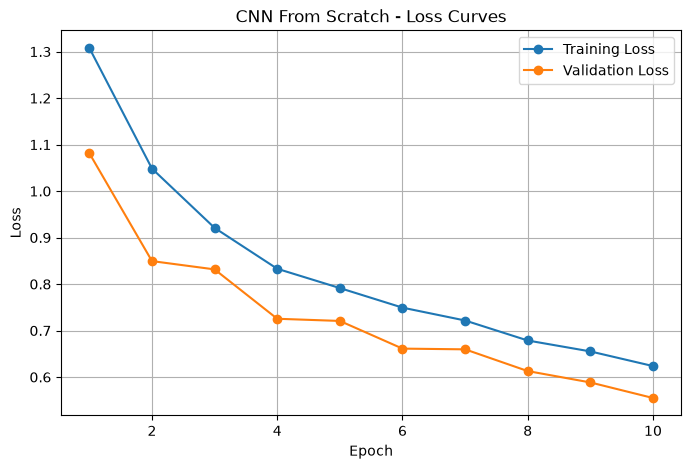

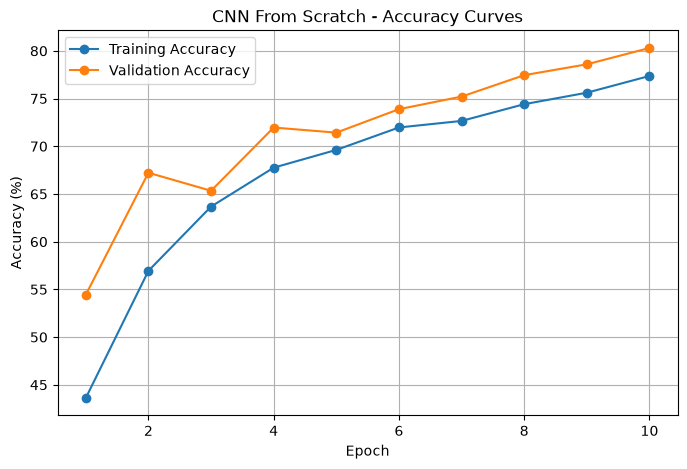

In [30]:

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# Plot 1: Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN From Scratch - Loss Curves")
plt.legend()
plt.grid(True)
plt.show()

# Plot 2: Training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    [x * 100 for x in history["train_accuracy"]],
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    epochs,
    [x * 100 for x in history["val_accuracy"]],
    marker="o",
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN From Scratch - Accuracy Curves")
plt.legend()
plt.grid(True)
plt.show()


In [31]:

from torchvision import datasets
from torch.utils.data import DataLoader

# Load the separate test dataset
test_dataset = datasets.ImageFolder(
    root=str(TEST_DIR),
    transform=eval_transform
)

# Create the test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Test images:", len(test_dataset))
print("Test classes:", test_dataset.classes)
print("Test batches:", len(test_loader))
print("Class mapping:", test_dataset.class_to_idx)


Test images: 3000
Test classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Test batches: 94
Class mapping: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


In [32]:

model.eval()

test_loss_total = 0.0
test_correct = 0
test_total = 0

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Get predictions
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)
        test_loss_total += loss.item() * images.size(0)

        # Predicted class
        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

        # Store predictions and actual labels on CPU
        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

test_loss = test_loss_total / test_total
test_accuracy = test_correct / test_total

print(f"Test images: {test_total}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Correct predictions: {test_correct}")
print(f"Incorrect predictions: {test_total - test_correct}")


Test images: 3000
Test loss: 0.5591
Test accuracy: 79.93%
Correct predictions: 2398
Incorrect predictions: 602


In [33]:

from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)



              precision    recall  f1-score   support

   buildings     0.7989    0.6911    0.7411       437
      forest     0.9218    0.9705    0.9455       474
     glacier     0.7885    0.7685    0.7784       553
    mountain     0.8117    0.7143    0.7599       525
         sea     0.7406    0.8902    0.8085       510
      street     0.7505    0.7625    0.7564       501

    accuracy                         0.7993      3000
   macro avg     0.8020    0.7995    0.7983      3000
weighted avg     0.8007    0.7993    0.7976      3000



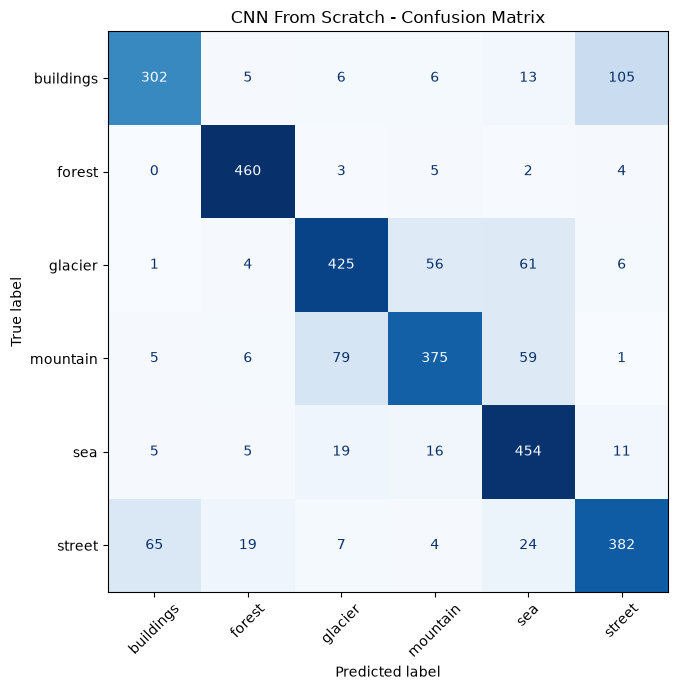

In [34]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

plt.title("CNN From Scratch - Confusion Matrix")
plt.tight_layout()
plt.show()


In [35]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# Find the indices where predictions were incorrect
all_labels_array = np.array(all_labels)
all_predictions_array = np.array(all_predictions)

wrong_indices = np.where(
    all_labels_array != all_predictions_array
)[0]

print("Total misclassified images:", len(wrong_indices))
print("Images to display:", min(10, len(wrong_indices)))

Total misclassified images: 602
Images to display: 10


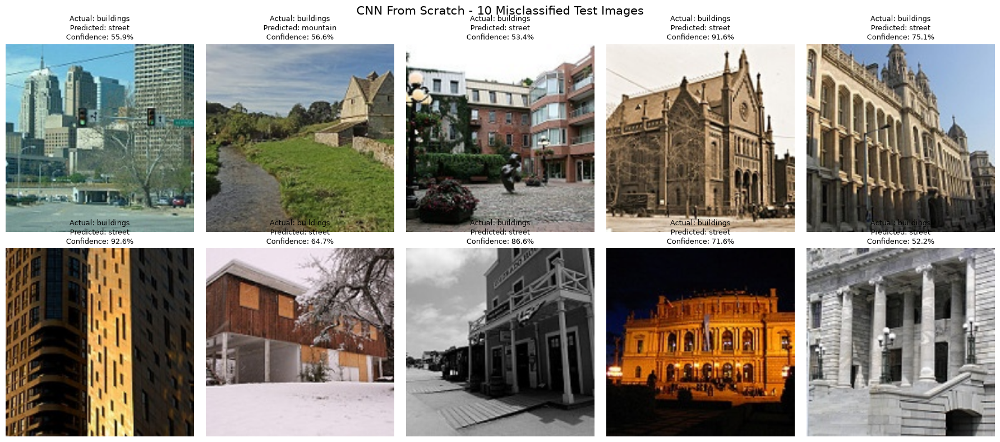

In [36]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# Get the first 10 misclassified image indices
indices_to_show = wrong_indices[:10]

# Keep model in evaluation mode
model.eval()

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for plot_idx, image_idx in enumerate(indices_to_show):

    # Get image and actual label from test dataset
    image, actual_label = test_dataset[image_idx]

    # Add batch dimension and move to GPU/CPU
    input_tensor = image.unsqueeze(0).to(device)

    # Predict class and confidence
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        predicted_label = outputs.argmax(dim=1).item()
        confidence = probabilities[0, predicted_label].item() * 100

    # Convert normalized tensor back for display
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    display_image = image.cpu() * std + mean
    display_image = display_image.permute(1, 2, 0).numpy()
    display_image = np.clip(display_image, 0, 1)

    # Display image and prediction details
    axes[plot_idx].imshow(display_image)
    axes[plot_idx].set_title(
        f"Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1f}%",
        fontsize=9
    )
    axes[plot_idx].axis("off")

plt.suptitle("CNN From Scratch - 10 Misclassified Test Images", fontsize=15)
plt.tight_layout()
plt.show()

In [38]:
from pathlib import Path
import torch

# Create models folder
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save trained CNN weights
cnn_model_path = MODELS_DIR / "cnn_baseline.pth"
torch.save(model.state_dict(), cnn_model_path)

print("CNN model saved successfully!")
print("Saved location:", cnn_model_path)
print("File exists:", cnn_model_path.exists())

CNN model saved successfully!
Saved location: D:\SS\Jupyter_ML\Intel_Image_Classification\models\cnn_baseline.pth
File exists: True


In [40]:
baseline_results = {
    "Model": "SimpleCNN - Baseline",
    "Epochs": NUM_EPOCHS,
    "Batch Size": BATCH_SIZE,
    "Learning Rate": LEARNING_RATE,
    "Dropout": 0.3,
    "Test Accuracy": test_accuracy,
    "Test Loss": test_loss
}

import pandas as pd

experiment_results = pd.DataFrame([baseline_results])

print(experiment_results.to_string(index=False))

               Model  Epochs  Batch Size  Learning Rate  Dropout  Test Accuracy  Test Loss
SimpleCNN - Baseline      10          32          0.001      0.3       0.799333   0.559061


In [41]:
import torch
import torch.nn as nn
import torch.optim as optim

# Experiment 1: Lower learning rate
LEARNING_RATE_EXP1 = 0.0005

model_exp1 = SimpleCNN(num_classes=6).to(device)

criterion_exp1 = nn.CrossEntropyLoss()

optimizer_exp1 = optim.Adam(
    model_exp1.parameters(),
    lr=LEARNING_RATE_EXP1
)

print("Experiment 1: Lower Learning Rate")
print("Learning rate:", LEARNING_RATE_EXP1)
print("Model device:", next(model_exp1.parameters()).device)
print("Optimizer:", optimizer_exp1)

Experiment 1: Lower Learning Rate
Learning rate: 0.0005
Model device: cuda:0
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0005
    maximize: False
    weight_decay: 0
)


In [42]:
NUM_EPOCHS_EXP1 = 10

history_exp1 = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS_EXP1):
    train_loss, train_acc = train_one_epoch(
        model_exp1,
        train_loader,
        criterion_exp1,
        optimizer_exp1,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model_exp1,
        val_loader,
        criterion_exp1,
        device
    )

    history_exp1["train_loss"].append(train_loss)
    history_exp1["val_loss"].append(val_loss)
    history_exp1["train_accuracy"].append(train_acc)
    history_exp1["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS_EXP1}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Accuracy: {train_acc * 100:.2f}% | "
        f"Val Accuracy: {val_acc * 100:.2f}%"
    )

Epoch [1/10] | Train Loss: 1.3868 | Val Loss: 1.1865 | Train Accuracy: 40.67% | Val Accuracy: 48.74%
Epoch [2/10] | Train Loss: 1.1754 | Val Loss: 1.0495 | Train Accuracy: 51.60% | Val Accuracy: 57.32%
Epoch [3/10] | Train Loss: 1.0619 | Val Loss: 0.9190 | Train Accuracy: 56.62% | Val Accuracy: 62.13%
Epoch [4/10] | Train Loss: 0.9756 | Val Loss: 0.8767 | Train Accuracy: 61.34% | Val Accuracy: 64.34%
Epoch [5/10] | Train Loss: 0.9290 | Val Loss: 0.8204 | Train Accuracy: 63.79% | Val Accuracy: 67.05%
Epoch [6/10] | Train Loss: 0.8795 | Val Loss: 0.8374 | Train Accuracy: 65.85% | Val Accuracy: 66.62%
Epoch [7/10] | Train Loss: 0.8394 | Val Loss: 0.7622 | Train Accuracy: 67.55% | Val Accuracy: 70.29%
Epoch [8/10] | Train Loss: 0.8014 | Val Loss: 0.7359 | Train Accuracy: 69.50% | Val Accuracy: 72.14%
Epoch [9/10] | Train Loss: 0.7788 | Val Loss: 0.7411 | Train Accuracy: 70.20% | Val Accuracy: 71.04%
Epoch [10/10] | Train Loss: 0.7489 | Val Loss: 0.6589 | Train Accuracy: 71.09% | Val Accura

In [43]:
experiment_1_results = {
    "Model": "SimpleCNN - Experiment 1",
    "Epochs": NUM_EPOCHS_EXP1,
    "Batch Size": BATCH_SIZE,
    "Learning Rate": LEARNING_RATE_EXP1,
    "Dropout": 0.3,
    "Final Train Accuracy": history_exp1["train_accuracy"][-1],
    "Final Validation Accuracy": history_exp1["val_accuracy"][-1],
    "Final Validation Loss": history_exp1["val_loss"][-1]
}

experiment_results = pd.concat(
    [
        experiment_results,
        pd.DataFrame([experiment_1_results])
    ],
    ignore_index=True
)

print(experiment_results.to_string(index=False))

                   Model  Epochs  Batch Size  Learning Rate  Dropout  Test Accuracy  Test Loss  Final Train Accuracy  Final Validation Accuracy  Final Validation Loss
    SimpleCNN - Baseline      10          32         0.0010      0.3       0.799333   0.559061                   NaN                        NaN                    NaN
SimpleCNN - Experiment 1      10          32         0.0005      0.3            NaN        NaN              0.710876                   0.752048               0.658906


In [44]:
# Experiment 2: Change batch size
BATCH_SIZE_EXP2 = 64
LEARNING_RATE_EXP2 = 0.001

from torch.utils.data import DataLoader

train_loader_exp2 = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE_EXP2,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

val_loader_exp2 = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE_EXP2,
    shuffle=False,
    num_workers=0
)

model_exp2 = SimpleCNN(num_classes=6).to(device)

criterion_exp2 = nn.CrossEntropyLoss()

optimizer_exp2 = optim.Adam(
    model_exp2.parameters(),
    lr=LEARNING_RATE_EXP2
)

print("Experiment 2 model ready!")
print("Batch size:", BATCH_SIZE_EXP2)
print("Learning rate:", LEARNING_RATE_EXP2)
print("Training batches:", len(train_loader_exp2))
print("Validation batches:", len(val_loader_exp2))

Experiment 2 model ready!
Batch size: 64
Learning rate: 0.001
Training batches: 176
Validation batches: 44


In [45]:
NUM_EPOCHS_EXP2 = 10

history_exp2 = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS_EXP2):
    train_loss, train_acc = train_one_epoch(
        model_exp2,
        train_loader_exp2,
        criterion_exp2,
        optimizer_exp2,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model_exp2,
        val_loader_exp2,
        criterion_exp2,
        device
    )

    history_exp2["train_loss"].append(train_loss)
    history_exp2["val_loss"].append(val_loss)
    history_exp2["train_accuracy"].append(train_acc)
    history_exp2["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS_EXP2}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

Epoch [1/10] | Train Loss: 1.3853 | Val Loss: 1.1553 | Train Acc: 41.18% | Val Acc: 49.45%
Epoch [2/10] | Train Loss: 1.1573 | Val Loss: 1.0214 | Train Acc: 52.85% | Val Acc: 57.07%
Epoch [3/10] | Train Loss: 1.0527 | Val Loss: 0.9470 | Train Acc: 57.74% | Val Acc: 61.24%
Epoch [4/10] | Train Loss: 0.9516 | Val Loss: 0.8577 | Train Acc: 62.25% | Val Acc: 66.08%
Epoch [5/10] | Train Loss: 0.9084 | Val Loss: 0.8341 | Train Acc: 64.34% | Val Acc: 67.33%
Epoch [6/10] | Train Loss: 0.8439 | Val Loss: 0.7865 | Train Acc: 66.87% | Val Acc: 69.43%
Epoch [7/10] | Train Loss: 0.8053 | Val Loss: 0.7585 | Train Acc: 69.07% | Val Acc: 70.89%
Epoch [8/10] | Train Loss: 0.7726 | Val Loss: 0.6890 | Train Acc: 70.13% | Val Acc: 71.32%
Epoch [9/10] | Train Loss: 0.7440 | Val Loss: 0.6969 | Train Acc: 72.09% | Val Acc: 72.11%
Epoch [10/10] | Train Loss: 0.7158 | Val Loss: 0.6255 | Train Acc: 73.05% | Val Acc: 76.70%


In [46]:
import pandas as pd

comparison_results = pd.DataFrame([
    {
        "Experiment": "Baseline",
        "Batch Size": 32,
        "Learning Rate": 0.001,
        "Final Train Accuracy (%)": history["train_accuracy"][-1] * 100,
        "Final Validation Accuracy (%)": history["val_accuracy"][-1] * 100,
        "Final Validation Loss": history["val_loss"][-1]
    },
    {
        "Experiment": "Experiment 1 - Lower LR",
        "Batch Size": 32,
        "Learning Rate": 0.0005,
        "Final Train Accuracy (%)": history_exp1["train_accuracy"][-1] * 100,
        "Final Validation Accuracy (%)": history_exp1["val_accuracy"][-1] * 100,
        "Final Validation Loss": history_exp1["val_loss"][-1]
    },
    {
        "Experiment": "Experiment 2 - Batch 64",
        "Batch Size": 64,
        "Learning Rate": 0.001,
        "Final Train Accuracy (%)": history_exp2["train_accuracy"][-1] * 100,
        "Final Validation Accuracy (%)": history_exp2["val_accuracy"][-1] * 100,
        "Final Validation Loss": history_exp2["val_loss"][-1]
    }
])

print(comparison_results.round(4).to_string(index=False))

             Experiment  Batch Size  Learning Rate  Final Train Accuracy (%)  Final Validation Accuracy (%)  Final Validation Loss
               Baseline          32         0.0010                   77.3671                        80.2993                 0.5550
Experiment 1 - Lower LR          32         0.0005                   71.0876                        75.2048                 0.6589
Experiment 2 - Batch 64          64         0.0010                   73.0471                        76.7011                 0.6255


In [47]:
# Experiment 3: Increase Dropout

class SimpleCNN_Exp3(nn.Module):
    def __init__(self, num_classes=6, dropout_rate=0.5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


DROPOUT_EXP3 = 0.5
LEARNING_RATE_EXP3 = 0.001
NUM_EPOCHS_EXP3 = 10

model_exp3 = SimpleCNN_Exp3(
    num_classes=6,
    dropout_rate=DROPOUT_EXP3
).to(device)

criterion_exp3 = nn.CrossEntropyLoss()

optimizer_exp3 = optim.Adam(
    model_exp3.parameters(),
    lr=LEARNING_RATE_EXP3
)

print("Experiment 3 model ready!")
print("Dropout:", DROPOUT_EXP3)
print("Learning rate:", LEARNING_RATE_EXP3)
print("Epochs:", NUM_EPOCHS_EXP3)

Experiment 3 model ready!
Dropout: 0.5
Learning rate: 0.001
Epochs: 10


In [48]:
history_exp3 = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS_EXP3):
    train_loss, train_acc = train_one_epoch(
        model_exp3,
        train_loader,
        criterion_exp3,
        optimizer_exp3,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model_exp3,
        val_loader,
        criterion_exp3,
        device
    )

    history_exp3["train_loss"].append(train_loss)
    history_exp3["val_loss"].append(val_loss)
    history_exp3["train_accuracy"].append(train_acc)
    history_exp3["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS_EXP3}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

Epoch [1/10] | Train Loss: 1.3463 | Val Loss: 1.1300 | Train Acc: 41.10% | Val Acc: 51.16%
Epoch [2/10] | Train Loss: 1.1475 | Val Loss: 0.9633 | Train Acc: 50.18% | Val Acc: 60.10%
Epoch [3/10] | Train Loss: 1.0552 | Val Loss: 0.8598 | Train Acc: 55.80% | Val Acc: 65.02%
Epoch [4/10] | Train Loss: 0.9603 | Val Loss: 0.8372 | Train Acc: 60.78% | Val Acc: 63.91%
Epoch [5/10] | Train Loss: 0.8946 | Val Loss: 0.7905 | Train Acc: 64.33% | Val Acc: 66.55%
Epoch [6/10] | Train Loss: 0.8567 | Val Loss: 0.7498 | Train Acc: 65.86% | Val Acc: 68.44%
Epoch [7/10] | Train Loss: 0.8347 | Val Loss: 0.7131 | Train Acc: 67.85% | Val Acc: 70.97%
Epoch [8/10] | Train Loss: 0.8061 | Val Loss: 0.6839 | Train Acc: 68.88% | Val Acc: 72.82%
Epoch [9/10] | Train Loss: 0.7861 | Val Loss: 0.6694 | Train Acc: 69.81% | Val Acc: 73.46%
Epoch [10/10] | Train Loss: 0.7437 | Val Loss: 0.6258 | Train Acc: 71.15% | Val Acc: 75.81%


In [49]:
comparison_results = pd.DataFrame([
    {
        "Experiment": "Baseline",
        "Batch Size": 32,
        "Learning Rate": 0.001,
        "Dropout": 0.3,
        "Train Accuracy (%)": history["train_accuracy"][-1] * 100,
        "Validation Accuracy (%)": history["val_accuracy"][-1] * 100,
        "Validation Loss": history["val_loss"][-1]
    },
    {
        "Experiment": "Experiment 1 - Lower LR",
        "Batch Size": 32,
        "Learning Rate": 0.0005,
        "Dropout": 0.3,
        "Train Accuracy (%)": history_exp1["train_accuracy"][-1] * 100,
        "Validation Accuracy (%)": history_exp1["val_accuracy"][-1] * 100,
        "Validation Loss": history_exp1["val_loss"][-1]
    },
    {
        "Experiment": "Experiment 2 - Batch 64",
        "Batch Size": 64,
        "Learning Rate": 0.001,
        "Dropout": 0.3,
        "Train Accuracy (%)": history_exp2["train_accuracy"][-1] * 100,
        "Validation Accuracy (%)": history_exp2["val_accuracy"][-1] * 100,
        "Validation Loss": history_exp2["val_loss"][-1]
    },
    {
        "Experiment": "Experiment 3 - Dropout 0.5",
        "Batch Size": 32,
        "Learning Rate": 0.001,
        "Dropout": 0.5,
        "Train Accuracy (%)": history_exp3["train_accuracy"][-1] * 100,
        "Validation Accuracy (%)": history_exp3["val_accuracy"][-1] * 100,
        "Validation Loss": history_exp3["val_loss"][-1]
    }
])

print(comparison_results.round(4).to_string(index=False))

                Experiment  Batch Size  Learning Rate  Dropout  Train Accuracy (%)  Validation Accuracy (%)  Validation Loss
                  Baseline          32         0.0010      0.3             77.3671                  80.2993           0.5550
   Experiment 1 - Lower LR          32         0.0005      0.3             71.0876                  75.2048           0.6589
   Experiment 2 - Batch 64          64         0.0010      0.3             73.0471                  76.7011           0.6255
Experiment 3 - Dropout 0.5          32         0.0010      0.5             71.1499                  75.8105           0.6258


In [50]:
from torchvision import models

print("ResNet-18 import successful!")
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)

ResNet-18 import successful!
CUDA available: True
Device: cuda


In [51]:
# Load pretrained ResNet-18

resnet_weights = models.ResNet18_Weights.DEFAULT

resnet_model = models.resnet18(weights=resnet_weights)

# Freeze all pretrained parameters
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace the final layer for our 6 classes
num_features = resnet_model.fc.in_features

resnet_model.fc = nn.Linear(num_features, len(class_names))

# Move model to GPU
resnet_model = resnet_model.to(device)

# Check trainable parameters
trainable_params = sum(
    p.numel() for p in resnet_model.parameters()
    if p.requires_grad
)

total_params = sum(p.numel() for p in resnet_model.parameters())

print("ResNet-18 loaded successfully!")
print("Classes:", class_names)
print("Output classes:", resnet_model.fc.out_features)
print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)
print("Device:", next(resnet_model.parameters()).device)

ResNet-18 loaded successfully!
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Output classes: 6
Trainable parameters: 3078
Total parameters: 11179590
Device: cuda:0


In [52]:
# Loss function
criterion_resnet = nn.CrossEntropyLoss()

# Optimize only the trainable (final layer) parameters
optimizer_resnet = optim.Adam(
    filter(lambda p: p.requires_grad, resnet_model.parameters()),
    lr=0.001
)

NUM_EPOCHS_RESNET = 5

print("ResNet-18 feature extraction setup complete!")
print("Learning rate: 0.001")
print("Epochs:", NUM_EPOCHS_RESNET)
print("Trainable parameters:", sum(
    p.numel() for p in resnet_model.parameters()
    if p.requires_grad
))

ResNet-18 feature extraction setup complete!
Learning rate: 0.001
Epochs: 5
Trainable parameters: 3078


In [53]:
history_resnet = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS_RESNET):
    train_loss, train_acc = train_one_epoch(
        resnet_model,
        train_loader,
        criterion_resnet,
        optimizer_resnet,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        resnet_model,
        val_loader,
        criterion_resnet,
        device
    )

    history_resnet["train_loss"].append(train_loss)
    history_resnet["val_loss"].append(val_loss)
    history_resnet["train_accuracy"].append(train_acc)
    history_resnet["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS_RESNET}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

Epoch [1/5] | Train Loss: 0.6095 | Val Loss: 0.3591 | Train Acc: 80.25% | Val Acc: 87.10%
Epoch [2/5] | Train Loss: 0.3768 | Val Loss: 0.2923 | Train Acc: 86.93% | Val Acc: 89.95%
Epoch [3/5] | Train Loss: 0.3482 | Val Loss: 0.2846 | Train Acc: 87.56% | Val Acc: 90.02%
Epoch [4/5] | Train Loss: 0.3308 | Val Loss: 0.2711 | Train Acc: 88.12% | Val Acc: 90.59%
Epoch [5/5] | Train Loss: 0.3199 | Val Loss: 0.2836 | Train Acc: 88.29% | Val Acc: 90.06%


In [54]:
from pathlib import Path
import torch

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

resnet_feature_path = MODELS_DIR / "resnet18_feature_extraction.pth"

torch.save({
    "model_state_dict": resnet_model.state_dict(),
    "class_names": class_names,
    "class_to_idx": class_to_idx,
    "image_size": CNN_IMAGE_SIZE,
    "validation_accuracy": history_resnet["val_accuracy"][-1],
    "best_validation_accuracy": max(history_resnet["val_accuracy"]),
    "training_method": "ResNet-18 Feature Extraction",
    "epochs_trained": NUM_EPOCHS_RESNET
}, resnet_feature_path)

print("ResNet-18 checkpoint saved!")
print("Path:", resnet_feature_path)
print("Saved model validation accuracy:",
      f"{history_resnet['val_accuracy'][-1] * 100:.2f}%")
print("Best recorded validation accuracy:",
      f"{max(history_resnet['val_accuracy']) * 100:.2f}%")

ResNet-18 checkpoint saved!
Path: D:\SS\Jupyter_ML\Intel_Image_Classification\models\resnet18_feature_extraction.pth
Saved model validation accuracy: 90.06%
Best recorded validation accuracy: 90.59%


In [55]:
# Load the saved feature-extraction checkpoint
checkpoint = torch.load(
    resnet_feature_path,
    map_location=device,
    weights_only=False
)

resnet_finetune = models.resnet18(
    weights=None
)

resnet_finetune.fc = nn.Linear(
    resnet_finetune.fc.in_features,
    len(class_names)
)

resnet_finetune.load_state_dict(
    checkpoint["model_state_dict"]
)

# Freeze every parameter first
for param in resnet_finetune.parameters():
    param.requires_grad = False

# Unfreeze the last residual block
for param in resnet_finetune.layer4.parameters():
    param.requires_grad = True

# Unfreeze the final classification layer
for param in resnet_finetune.fc.parameters():
    param.requires_grad = True

resnet_finetune = resnet_finetune.to(device)

trainable_params = sum(
    p.numel()
    for p in resnet_finetune.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in resnet_finetune.parameters()
)

print("ResNet-18 fine-tuning model ready!")
print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)
print("Trainable layers: layer4 and fc")
print("Device:", next(resnet_finetune.parameters()).device)

ResNet-18 fine-tuning model ready!
Trainable parameters: 8396806
Total parameters: 11179590
Trainable layers: layer4 and fc
Device: cuda:0


In [56]:
# Fine-tuning configuration
NUM_EPOCHS_FINETUNE = 5
LEARNING_RATE_FINETUNE = 0.0001

criterion_finetune = nn.CrossEntropyLoss()

optimizer_finetune = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet_finetune.parameters()
    ),
    lr=LEARNING_RATE_FINETUNE
)

history_finetune = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

print("Fine-tuning setup complete!")
print("Epochs:", NUM_EPOCHS_FINETUNE)
print("Learning rate:", LEARNING_RATE_FINETUNE)
print("Optimizer: Adam")
print("Loss function: CrossEntropyLoss")

Fine-tuning setup complete!
Epochs: 5
Learning rate: 0.0001
Optimizer: Adam
Loss function: CrossEntropyLoss


In [57]:
for epoch in range(NUM_EPOCHS_FINETUNE):
    train_loss, train_acc = train_one_epoch(
        resnet_finetune,
        train_loader,
        criterion_finetune,
        optimizer_finetune,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        resnet_finetune,
        val_loader,
        criterion_finetune,
        device
    )

    history_finetune["train_loss"].append(train_loss)
    history_finetune["val_loss"].append(val_loss)
    history_finetune["train_accuracy"].append(train_acc)
    history_finetune["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS_FINETUNE}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

Epoch [1/5] | Train Loss: 0.2850 | Val Loss: 0.2307 | Train Acc: 89.90% | Val Acc: 91.95%
Epoch [2/5] | Train Loss: 0.1772 | Val Loss: 0.2167 | Train Acc: 93.76% | Val Acc: 92.48%
Epoch [3/5] | Train Loss: 0.1344 | Val Loss: 0.2504 | Train Acc: 94.99% | Val Acc: 92.09%
Epoch [4/5] | Train Loss: 0.1124 | Val Loss: 0.2253 | Train Acc: 95.86% | Val Acc: 93.16%
Epoch [5/5] | Train Loss: 0.0826 | Val Loss: 0.2632 | Train Acc: 96.97% | Val Acc: 91.73%


In [58]:
finetune_model_path = MODELS_DIR / "resnet18_finetuned.pth"

torch.save({
    "model_state_dict": resnet_finetune.state_dict(),
    "class_names": class_names,
    "class_to_idx": class_to_idx,
    "image_size": CNN_IMAGE_SIZE,
    "validation_accuracy": history_finetune["val_accuracy"][-1],
    "best_recorded_validation_accuracy": max(
        history_finetune["val_accuracy"]
    ),
    "training_method": "ResNet-18 Fine-Tuning",
    "epochs_trained": NUM_EPOCHS_FINETUNE
}, finetune_model_path)

print("Fine-tuned ResNet-18 saved!")
print("Path:", finetune_model_path)
print(
    "Final validation accuracy:",
    f"{history_finetune['val_accuracy'][-1] * 100:.2f}%"
)
print(
    "Best recorded validation accuracy:",
    f"{max(history_finetune['val_accuracy']) * 100:.2f}%"
)

Fine-tuned ResNet-18 saved!
Path: D:\SS\Jupyter_ML\Intel_Image_Classification\models\resnet18_finetuned.pth
Final validation accuracy: 91.73%
Best recorded validation accuracy: 93.16%


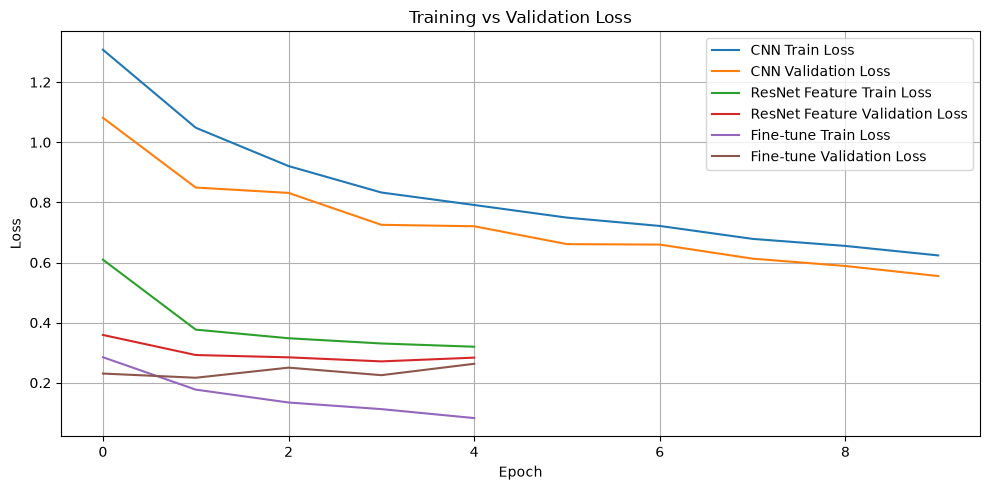

<module 'matplotlib.pyplot' from 'C:\\Users\\ASUS\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\matplotlib\\pyplot.py'>

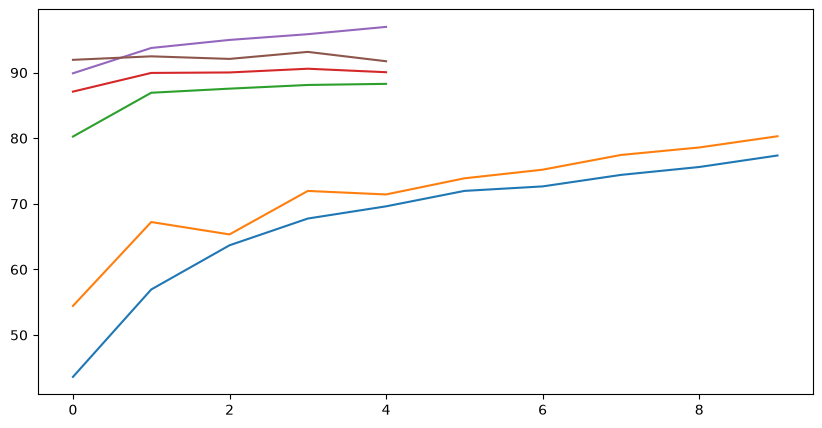

In [59]:
import matplotlib.pyplot as plt

# Compare training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="CNN Train Loss")
plt.plot(history["val_loss"], label="CNN Validation Loss")

plt.plot(history_resnet["train_loss"], label="ResNet Feature Train Loss")
plt.plot(history_resnet["val_loss"], label="ResNet Feature Validation Loss")

plt.plot(history_finetune["train_loss"], label="Fine-tune Train Loss")
plt.plot(history_finetune["val_loss"], label="Fine-tune Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Compare training and validation accuracy
plt.figure(figsize=(10, 5))

plt.plot(
    [x * 100 for x in history["train_accuracy"]],
    label="CNN Train Accuracy"
)
plt.plot(
    [x * 100 for x in history["val_accuracy"]],
    label="CNN Validation Accuracy"
)

plt.plot(
    [x * 100 for x in history_resnet["train_accuracy"]],
    label="ResNet Feature Train Accuracy"
)
plt.plot(
    [x * 100 for x in history_resnet["val_accuracy"]],
    label="ResNet Feature Validation Accuracy"
)

plt.plot(
    [x * 100 for x in history_finetune["train_accuracy"]],
    label="Fine-tune Train Accuracy"
)
plt.plot(
    [x * 100 for x in history_finetune["val_accuracy"]],
    label="Fine-tune Validation Accuracy"
)

plt

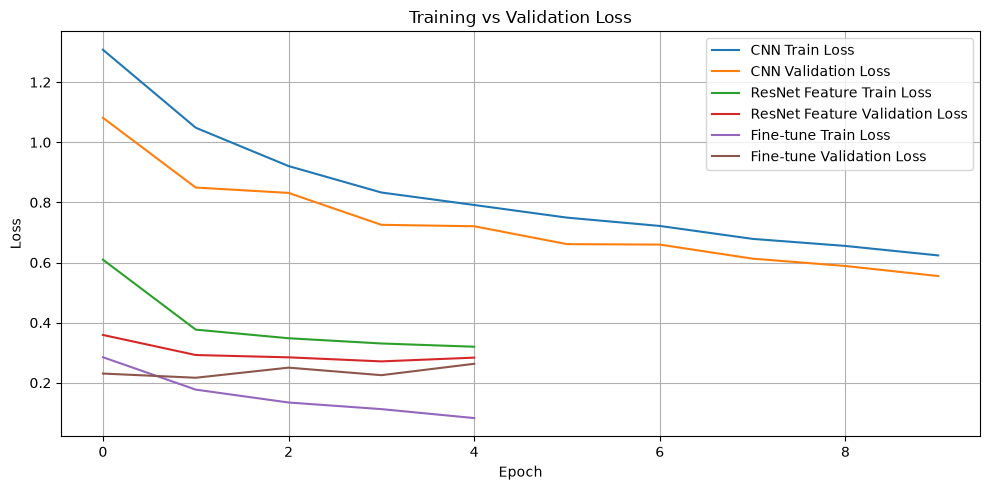

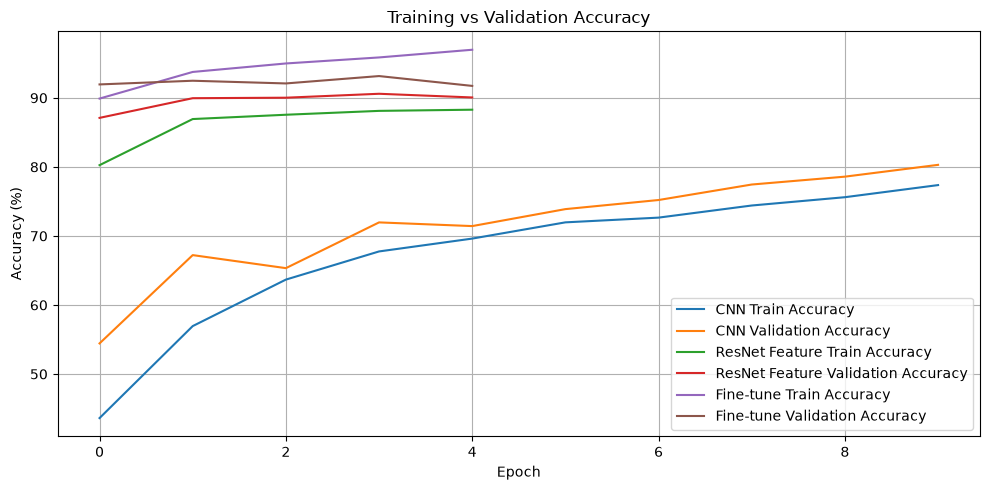

Graphs saved in: D:\SS\Jupyter_ML\Intel_Image_Classification\outputs\plots


In [60]:
from pathlib import Path

PLOTS_DIR = PROJECT_DIR / "outputs" / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the loss graph
plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"], label="CNN Train Loss")
plt.plot(history["val_loss"], label="CNN Validation Loss")
plt.plot(history_resnet["train_loss"], label="ResNet Feature Train Loss")
plt.plot(history_resnet["val_loss"], label="ResNet Feature Validation Loss")
plt.plot(history_finetune["train_loss"], label="Fine-tune Train Loss")
plt.plot(history_finetune["val_loss"], label="Fine-tune Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "training_validation_loss.png", dpi=300)
plt.show()

# Save the accuracy graph
plt.figure(figsize=(10, 5))
plt.plot([x * 100 for x in history["train_accuracy"]], label="CNN Train Accuracy")
plt.plot([x * 100 for x in history["val_accuracy"]], label="CNN Validation Accuracy")
plt.plot([x * 100 for x in history_resnet["train_accuracy"]], label="ResNet Feature Train Accuracy")
plt.plot([x * 100 for x in history_resnet["val_accuracy"]], label="ResNet Feature Validation Accuracy")
plt.plot([x * 100 for x in history_finetune["train_accuracy"]], label="Fine-tune Train Accuracy")
plt.plot([x * 100 for x in history_finetune["val_accuracy"]], label="Fine-tune Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "training_validation_accuracy.png", dpi=300)
plt.show()

print("Graphs saved in:", PLOTS_DIR)

Test Accuracy: 79.93%

Classification Report:
              precision    recall  f1-score   support

   buildings     0.7989    0.6911    0.7411       437
      forest     0.9218    0.9705    0.9455       474
     glacier     0.7885    0.7685    0.7784       553
    mountain     0.8117    0.7143    0.7599       525
         sea     0.7406    0.8902    0.8085       510
      street     0.7505    0.7625    0.7564       501

    accuracy                         0.7993      3000
   macro avg     0.8020    0.7995    0.7983      3000
weighted avg     0.8007    0.7993    0.7976      3000



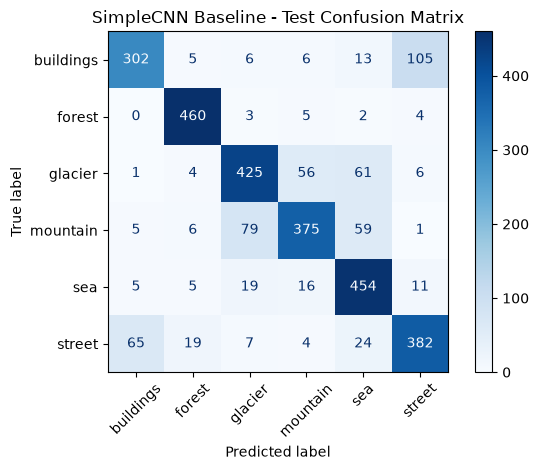

In [61]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import numpy as np
import matplotlib.pyplot as plt
import torch

def evaluate_model(model, loader, device, class_names):
    model.eval()
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_predictions)

    print(f"Test Accuracy: {accuracy * 100:.2f}%")
    print("\nClassification Report:")
    print(classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names)))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )
    disp.plot(cmap="Blues", xticks_rotation=45)
    plt.title("SimpleCNN Baseline - Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return accuracy, all_labels, all_predictions, cm


cnn_test_accuracy, cnn_test_labels, cnn_test_predictions, cnn_cm = (
    evaluate_model(model, test_loader, device, class_names)
)

Test Accuracy: 92.63%

Classification Report:
              precision    recall  f1-score   support

   buildings     0.8703    0.9519    0.9093       437
      forest     0.9979    0.9895    0.9936       474
     glacier     0.8640    0.9078    0.8854       553
    mountain     0.9184    0.8571    0.8867       525
         sea     0.9635    0.9843    0.9738       510
      street     0.9565    0.8782    0.9157       501

    accuracy                         0.9263      3000
   macro avg     0.9284    0.9281    0.9274      3000
weighted avg     0.9280    0.9263    0.9263      3000



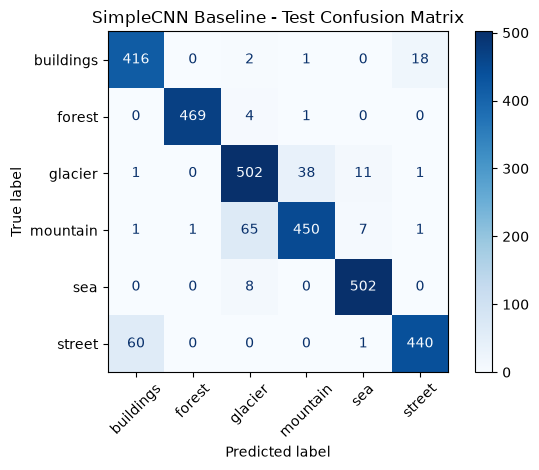

In [62]:
resnet_test_accuracy, resnet_test_labels, resnet_test_predictions, resnet_cm = (
    evaluate_model(
        resnet_finetune,
        test_loader,
        device,
        class_names
    )
)

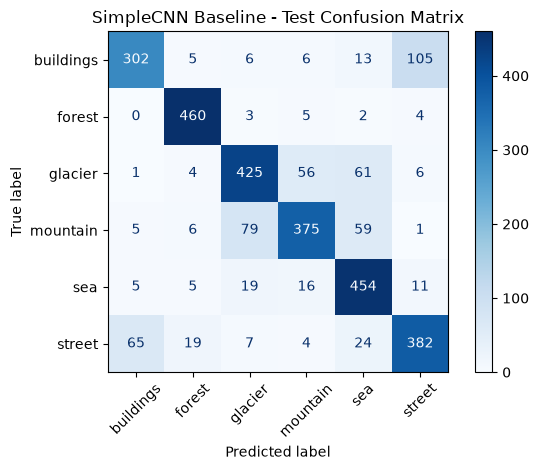

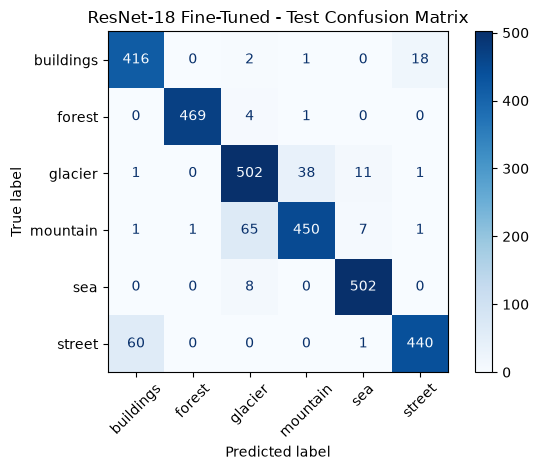

Confusion matrices saved in: D:\SS\Jupyter_ML\Intel_Image_Classification\outputs\confusion_matrices


In [63]:
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

CM_DIR = PROJECT_DIR / "outputs" / "confusion_matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

# Save SimpleCNN confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cnn_cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("SimpleCNN Baseline - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(CM_DIR / "cnn_test_confusion_matrix.png", dpi=300)
plt.show()

# Save ResNet-18 confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=resnet_cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("ResNet-18 Fine-Tuned - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(CM_DIR / "resnet18_test_confusion_matrix.png", dpi=300)
plt.show()

print("Confusion matrices saved in:", CM_DIR)

In [64]:
import torch
import matplotlib.pyplot as plt
import numpy as np

resnet_finetune.eval()

wrong_indices = []
wrong_predictions = []
wrong_confidences = []

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):
        images_gpu = images.to(device)
        outputs = resnet_finetune(images_gpu)
        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        for i in range(len(labels)):
            if predictions[i].cpu().item() != labels[i].item():
                wrong_indices.append(batch_idx * test_loader.batch_size + i)
                wrong_predictions.append(predictions[i].cpu().item())
                wrong_confidences.append(
                    probabilities[i, predictions[i]].cpu().item()
                )

print("Total misclassified test images:", len(wrong_indices))
print("Showing first 10 misclassified images.")

Total misclassified test images: 221
Showing first 10 misclassified images.


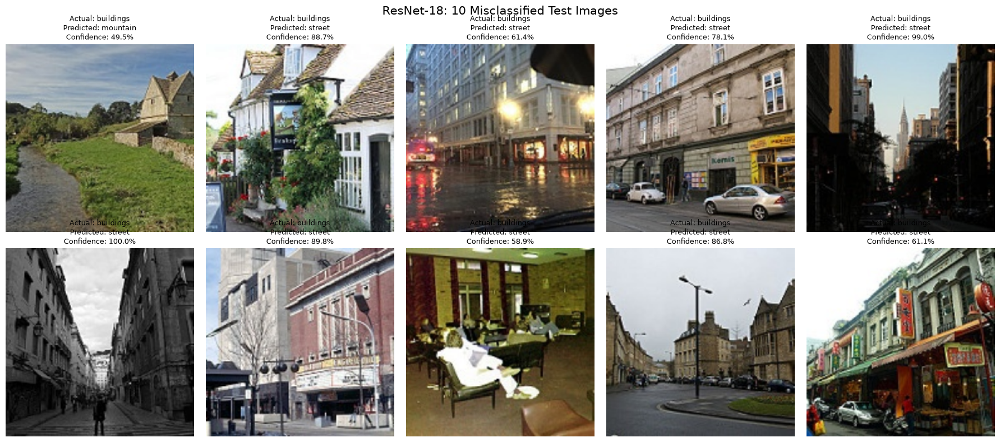

In [65]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# ImageNet normalization reverse karva mate
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

resnet_finetune.eval()

for plot_idx, test_idx in enumerate(wrong_indices[:10]):
    image, actual_label = test_dataset[test_idx]

    # Display image in original visual scale
    image_display = image.cpu() * std + mean
    image_display = image_display.clamp(0, 1).permute(1, 2, 0).numpy()

    predicted_label = wrong_predictions[plot_idx]
    confidence = wrong_confidences[plot_idx] * 100

    axes[plot_idx].imshow(image_display)
    axes[plot_idx].set_title(
        f"Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1f}%",
        fontsize=9
    )
    axes[plot_idx].axis("off")

plt.suptitle("ResNet-18: 10 Misclassified Test Images", fontsize=15)
plt.tight_layout()
plt.show()

In [66]:
import pandas as pd

error_analysis = []

for i in range(min(10, len(wrong_indices))):
    test_idx = wrong_indices[i]
    actual_label = test_dataset[test_idx][1]
    predicted_label = wrong_predictions[i]
    confidence = wrong_confidences[i] * 100

    error_analysis.append({
        "Image Number": test_idx,
        "Actual Class": class_names[actual_label],
        "Predicted Class": class_names[predicted_label],
        "Confidence (%)": round(confidence, 2)
    })

error_df = pd.DataFrame(error_analysis)

print(error_df.to_string(index=False))

# Save the error analysis
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

error_df.to_csv(
    METRICS_DIR / "resnet18_misclassified_images.csv",
    index=False
)

print("\nError analysis saved!")
print("Path:", METRICS_DIR / "resnet18_misclassified_images.csv")

 Image Number Actual Class Predicted Class  Confidence (%)
            5    buildings        mountain           49.53
           63    buildings          street           88.66
           77    buildings          street           61.42
           85    buildings          street           78.06
           86    buildings          street           98.98
           88    buildings          street          100.00
           93    buildings          street           89.76
          119    buildings          street           58.94
          153    buildings          street           86.81
          163    buildings          street           61.08

Error analysis saved!
Path: D:\SS\Jupyter_ML\Intel_Image_Classification\outputs\metrics\resnet18_misclassified_images.csv


In [93]:
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import torch
import matplotlib.pyplot as plt
import pandas as pd


def predict_image(image_path, model, transform, class_names, device):
    image_path = Path(image_path)

    # Check whether the file exists
    if not image_path.is_file():
        print(f"Error: Image file not found: {image_path}")
        return None, None

    # Safely open and validate the image
    try:
        with Image.open(image_path) as img:
            image = img.convert("RGB")
    except (OSError, UnidentifiedImageError) as e:
        print(f"Error: Could not open a valid image. Details: {e}")
        return None, None

    model.eval()
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_idx = probabilities.argmax().item()
    predicted_class = class_names[predicted_idx]

    results = pd.DataFrame({
        "Class": class_names,
        "Confidence (%)": (
            probabilities.cpu().numpy() * 100
        ).round(2)
    }).sort_values("Confidence (%)", ascending=False)

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(f"Predicted: {predicted_class}")
    plt.axis("off")
    plt.show()

    print("Predicted Class:", predicted_class)
    print("\nConfidence Scores:")
    print(results.to_string(index=False))

    return predicted_class, results

Selected image: 17218.jpg


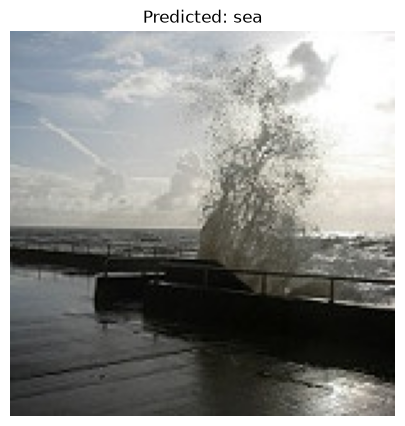

Predicted Class: sea

Confidence Scores:
    Class  Confidence (%)
      sea       81.470001
   street        9.980000
buildings        6.360000
  glacier        1.870000
 mountain        0.170000
   forest        0.150000


In [71]:
import random

# Select one unseen image
sample_image_path = random.choice(pred_images)

print("Selected image:", sample_image_path.name)

# Predict using fine-tuned ResNet-18
predicted_class, confidence_scores = predict_image(
    image_path=sample_image_path,
    model=resnet_model,
    transform=eval_transform,
    class_names=class_names,
    device=device
)

In [72]:
import random
import pandas as pd
import torch
from PIL import Image

# Select 10 different unseen images
random.seed(42)
sample_images = random.sample(pred_images, 10)

prediction_results = []

resnet_model.eval()

for image_path in sample_images:
    image = Image.open(image_path).convert("RGB")
    image_tensor = eval_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = resnet_model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0].cpu().numpy()

    predicted_idx = int(probabilities.argmax())

    row = {
        "Image": image_path.name,
        "Predicted Class": class_names[predicted_idx]
    }

    for i, class_name in enumerate(class_names):
        row[f"{class_name} (%)"] = round(float(probabilities[i] * 100), 2)

    prediction_results.append(row)

prediction_df = pd.DataFrame(prediction_results)

print(prediction_df.to_string(index=False))

    Image Predicted Class  buildings (%)  forest (%)  glacier (%)  mountain (%)  sea (%)  street (%)
 4021.jpg          street           0.44        0.00         0.00          0.00     0.00       99.56
12921.jpg          street           4.61        0.00         0.00          0.00     0.00       95.39
10677.jpg         glacier           0.00        0.00        82.91         16.98     0.11        0.00
 6365.jpg             sea           0.00        0.00         0.02          0.00    99.98        0.00
  169.jpg       buildings          73.20        0.02         0.02          0.10     0.09       26.56
16167.jpg          street           0.10        0.00         0.00          0.00     0.00       99.90
15632.jpg             sea           0.00        0.02         1.22          0.20    98.55        0.01
13542.jpg          forest           0.02       98.86         0.02          0.05     0.13        0.93
 6234.jpg             sea           0.03        0.00         0.21          0.08    99.63   

In [73]:
# Save predictions for 10 unseen images
METRICS_DIR = PROJECT_DIR / "outputs" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

prediction_csv_path = METRICS_DIR / "resnet18_unseen_predictions.csv"

prediction_df.to_csv(prediction_csv_path, index=False)

print("10 unseen image predictions saved successfully!")
print("File path:", prediction_csv_path)
print("Total predictions:", len(prediction_df))

10 unseen image predictions saved successfully!
File path: D:\SS\Jupyter_ML\Intel_Image_Classification\outputs\metrics\resnet18_unseen_predictions.csv
Total predictions: 10


In [74]:
from pathlib import Path

required_files = {
    "CNN baseline weights": PROJECT_DIR / "models" / "cnn_baseline.pth",
    "ResNet feature extraction weights": PROJECT_DIR / "models" / "resnet18_feature_extraction.pth",
    "ResNet fine-tuned weights": PROJECT_DIR / "models" / "resnet18_finetuned.pth",
    "CNN confusion matrix": PROJECT_DIR / "outputs" / "confusion_matrices" / "cnn_test_confusion_matrix.png",
    "ResNet confusion matrix": PROJECT_DIR / "outputs" / "confusion_matrices" / "resnet18_test_confusion_matrix.png",
    "Training loss curves": PROJECT_DIR / "outputs" / "plots" / "training_validation_loss.png",
    "Training accuracy curves": PROJECT_DIR / "outputs" / "plots" / "training_validation_accuracy.png",
    "Misclassified images CSV": PROJECT_DIR / "outputs" / "metrics" / "resnet18_misclassified_images.csv",
    "Unseen predictions CSV": PROJECT_DIR / "outputs" / "metrics" / "resnet18_unseen_predictions.csv",
}

for name, path in required_files.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status:7} | {name}")

print("\nExisting files:", sum(p.exists() for p in required_files.values()),
      "/", len(required_files))

FOUND   | CNN baseline weights
FOUND   | ResNet feature extraction weights
FOUND   | ResNet fine-tuned weights
FOUND   | CNN confusion matrix
FOUND   | ResNet confusion matrix
FOUND   | Training loss curves
FOUND   | Training accuracy curves
FOUND   | Misclassified images CSV
FOUND   | Unseen predictions CSV

Existing files: 9 / 9


In [75]:
README_PATH = PROJECT_DIR / "README.md"

readme_content = """
# Intel Image Classification

## Project Overview
This project classifies natural scene images into six categories
using a CNN built from scratch and a pretrained ResNet-18 model.

## Classes
- Buildings
- Forest
- Glacier
- Mountain
- Sea
- Street

## Dataset
- Training images: 14,034
- Validation images: 2,807
- Test images: 3,000
- Unseen prediction images: 7,301

The original training dataset was split into training and validation
subsets. The separate test dataset was reserved for final evaluation.

## Models
1. SimpleCNN built from scratch
2. ResNet-18 feature extraction
3. ResNet-18 fine-tuning

## Final Test Results

| Metric | CNN | Fine-tuned ResNet-18 |
|---|---:|---:|
| Accuracy | 79.93% | 92.63% |
| Macro F1-score | 79.83% | 92.74% |
| Weighted F1-score | 79.76% | 92.63% |

## Project Outputs
- models/: saved model weights
- outputs/plots/: training and validation curves
- outputs/confusion_matrices/: test confusion matrices
- outputs/metrics/: error analysis and unseen predictions

## Prediction
The notebook includes a reusable prediction function that returns
the predicted class and confidence scores for all six categories.

The seg_pred images are unlabeled, so their prediction accuracy
cannot be verified from the dataset alone.

## Technologies
- Python
- PyTorch
- Torchvision
- NumPy
- Pandas
- Matplotlib
- Scikit-learn

## Reproducibility
The notebook uses a fixed random seed for the train-validation split.
Run the notebook cells in order after configuring the dataset paths
and installing the required libraries.
"""

README_PATH.write_text(readme_content.strip(), encoding="utf-8")

print("README created successfully!")
print("Path:", README_PATH)
print("\nPreview:\n")
print(README_PATH.read_text(encoding="utf-8")[:1000])

README created successfully!
Path: D:\SS\Jupyter_ML\Intel_Image_Classification\README.md

Preview:

# Intel Image Classification

## Project Overview
This project classifies natural scene images into six categories
using a CNN built from scratch and a pretrained ResNet-18 model.

## Classes
- Buildings
- Forest
- Glacier
- Mountain
- Sea
- Street

## Dataset
- Training images: 14,034
- Validation images: 2,807
- Test images: 3,000
- Unseen prediction images: 7,301

The original training dataset was split into training and validation
subsets. The separate test dataset was reserved for final evaluation.

## Models
1. SimpleCNN built from scratch
2. ResNet-18 feature extraction
3. ResNet-18 fine-tuning

## Final Test Results

| Metric | CNN | Fine-tuned ResNet-18 |
|---|---:|---:|
| Accuracy | 79.93% | 92.63% |
| Macro F1-score | 79.83% | 92.74% |
| Weighted F1-score | 79.76% | 92.63% |

## Project Outputs
- models/: saved model weights
- outputs/plots/: training and validation curves
- o

In [76]:
REPORT_PATH = PROJECT_DIR / "Technical_Report.md"

report_content = """
# Intel Image Classification — Technical Report

## 1. Objective
The objective is to classify natural scene images into six classes:
buildings, forest, glacier, mountain, sea, and street.

Two approaches were evaluated:
- SimpleCNN trained from scratch
- ResNet-18 using transfer learning and fine-tuning

## 2. Dataset and Preparation
- Original training images: 14,034
- Training split: 11,227
- Validation split: 2,807
- Separate test images: 3,000
- Unlabeled prediction images: 7,301
- Number of classes: 6
- Corrupted images found during initial checking: 0

Images were resized to 224 x 224 pixels. Training data used
random horizontal flipping, random rotation, and color jitter.
Images were converted to tensors and normalized.

The test dataset was kept separate from training and validation.

## 3. Models

### SimpleCNN
A custom CNN was built using convolutional layers, ReLU activation,
max pooling, adaptive average pooling, and fully connected layers.
Dropout (0.3) was used in the classifier.

- Trainable parameters: 101,894
- Optimizer: Adam
- Learning rate: 0.001
- Loss function: CrossEntropyLoss
- Batch size: 32
- Training epochs: 10

### ResNet-18 Feature Extraction
Pretrained ResNet-18 weights were used. The pretrained backbone
was frozen and the final classification layer was replaced to
predict six classes.

- Total parameters: 11,179,590
- Trainable parameters: 3,078
- Training epochs: 5

### ResNet-18 Fine-Tuning
The ResNet-18 layer4 block and final classification layer were
unfrozen and trained with a learning rate of 0.0001 for 5 epochs.

- Total parameters: 11,179,590
- Trainable parameters: 8,396,806

## 4. Hyperparameter Experiments
Three controlled experiments were compared with the baseline CNN.

| Experiment | Learning Rate | Batch Size | Dropout | Validation Accuracy |
|---|---:|---:|---:|---:|
| Baseline | 0.001 | 32 | 0.3 | 80.30% |
| Lower learning rate | 0.0005 | 32 | 0.3 | 75.20% |
| Larger batch | 0.001 | 64 | 0.3 | 76.70% |
| Higher dropout | 0.001 | 32 | 0.5 | 75.81% |

The baseline configuration achieved the highest validation accuracy
among these experiments.

## 5. Final Test Results

| Metric | SimpleCNN | Fine-tuned ResNet-18 |
|---|---:|---:|
| Accuracy | 79.93% | 92.63% |
| Macro Precision | 80.20% | 92.84% |
| Macro Recall | 79.95% | 92.81% |
| Macro F1-score | 79.83% | 92.74% |
| Weighted F1-score | 79.76% | 92.63% |
| Correct predictions | 2,398 / 3,000 | 2,779 / 3,000 |

Fine-tuned ResNet-18 improved test accuracy by 12.70 percentage points
compared with the custom CNN.

## 6. Per-Class Results: Fine-Tuned ResNet-18

| Class | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Buildings | 87.03% | 95.19% | 90.93% |
| Forest | 99.79% | 98.95% | 99.36% |
| Glacier | 86.40% | 90.78% | 88.54% |
| Mountain | 91.84% | 85.71% | 88.67% |
| Sea | 96.35% | 98.43% | 97.38% |
| Street | 95.65% | 87.82% | 91.57% |

Forest and sea had the strongest results. Mountain and glacier
were relatively more challenging, while buildings and street
still had some classification errors.

## 7. Error Analysis
The fine-tuned ResNet-18 incorrectly classified 221 of the 3,000
test images. The first 10 misclassified examples and their predicted
classes and confidence scores were saved to:
outputs/metrics/resnet18_misclassified_images.csv

The model sometimes confuses visually similar scenes. Confidence
scores should not be interpreted as guarantees of correctness.

## 8. Unseen Image Predictions
A reusable prediction function was created. It returns a predicted
class and confidence scores for all six classes.

Predictions for 10 unlabeled images from seg_pred were saved to:
outputs/metrics/resnet18_unseen_predictions.csv

These images have no provided labels, so their accuracy could not
be measured.

## 9. Generalization and Regularization
Training augmentation (horizontal flips, rotation, and color jitter)
increases variation in training examples. Dropout helps reduce
co-adaptation of neurons in the CNN classifier.

The higher-dropout experiment achieved lower validation accuracy
than the baseline in the tested setup. Fine-tuning showed a gap
between training and validation performance in later epochs,
suggesting possible overfitting.

## 10. Reproducibility and Saved Artifacts
The train-validation split used a fixed random seed. Model weights,
training curves, confusion matrices, and prediction/error-analysis
CSVs were saved in the project directory.

Saved models:
- models/cnn_baseline.pth
- models/resnet18_feature_extraction.pth
- models/resnet18_finetuned.pth

Plots:
- outputs/plots/training_validation_loss.png
- outputs/plots/training_validation_accuracy.png

Confusion matrices:
- outputs/confusion_matrices/cnn_test_confusion_matrix.png
- outputs/confusion_matrices/resnet18_test_confusion_matrix.png

## 11. Limitations and Future Improvements
- The unlabeled prediction set cannot be quantitatively evaluated.
- Confidence scores can be high even for incorrect predictions.
- The saved ResNet checkpoints contain the final training epoch,
  not necessarily the epoch with the highest validation accuracy.
- Future work should save the best checkpoint during training,
  tune hyperparameters further, inspect more errors, and test
  additional augmentation and regularization strategies.

## 12. Conclusion
Fine-tuned ResNet-18 performed substantially better than the
custom CNN on the held-out test set, reaching 92.63% accuracy.
Transfer learning provided a strong starting point for scene
classification. Error analysis and best-checkpoint saving remain
important areas for further improvement.
"""

REPORT_PATH.write_text(report_content.strip(), encoding="utf-8")

print("Technical report created successfully!")
print("Path:", REPORT_PATH)
print("File size:", round(REPORT_PATH.stat().st_size / 1024, 2), "KB")

Technical report created successfully!
Path: D:\SS\Jupyter_ML\Intel_Image_Classification\Technical_Report.md
File size: 5.63 KB


In [77]:
# Check existing CNN experiment results

print("Baseline CNN:")
print("Train Accuracy:", round(77.3671, 2), "%")
print("Validation Accuracy:", round(80.2993, 2), "%")

print("\nHigher Dropout Experiment (Dropout = 0.5):")
print("Train Accuracy:", round(71.1499, 2), "%")
print("Validation Accuracy:", round(75.8105, 2), "%")

Baseline CNN:
Train Accuracy: 77.37 %
Validation Accuracy: 80.3 %

Higher Dropout Experiment (Dropout = 0.5):
Train Accuracy: 71.15 %
Validation Accuracy: 75.81 %


In [82]:
import pandas as pd

regularization_comparison = pd.DataFrame({
    "Experiment": [
        "Baseline CNN (Dropout = 0.3)",
        "Higher Dropout CNN (Dropout = 0.5)"
    ],
    "Train Accuracy (%)": [77.3671, 71.1499],
    "Validation Accuracy (%)": [80.2993, 75.8105]
})

print(regularization_comparison.to_string(index=False))

                        Experiment  Train Accuracy (%)  Validation Accuracy (%)
      Baseline CNN (Dropout = 0.3)             77.3671                  80.2993
Higher Dropout CNN (Dropout = 0.5)             71.1499                  75.8105


In [83]:
# Check augmentation settings used in the project

print("Training Transform:")
print(train_transform)

print("\nValidation Transform:")
print(eval_transform)

Training Transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation Transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [88]:
from pathlib import Path

MODELS_DIR = PROJECT_DIR / "models"

for path in sorted(MODELS_DIR.glob("*.pth")):
    print(f"{path.name} — {path.stat().st_size / (1024 * 1024):.2f} MB")

cnn_baseline.pth — 0.39 MB
resnet18_feature_extraction.pth — 42.73 MB
resnet18_finetuned.pth — 42.72 MB


In [89]:
print("CNN best validation accuracy:",
      max(history["val_accuracy"]) * 100, "%")

print("ResNet feature extraction best validation accuracy:",
      max(history_resnet["val_accuracy"]) * 100, "%")

print("ResNet fine-tuning best validation accuracy:",
      max(history_finetune["val_accuracy"]) * 100, "%")

CNN best validation accuracy: 80.29925187032418 %
ResNet feature extraction best validation accuracy: 90.59494121838262 %
ResNet fine-tuning best validation accuracy: 93.1599572497328 %


In [91]:
checkpoint = torch.load(
    finetune_model_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", checkpoint.keys())

if "validation_accuracy" in checkpoint:
    print("Saved validation accuracy:",
          checkpoint["validation_accuracy"] * 100, "%")

if "best_validation_accuracy" in checkpoint:
    print("Recorded best validation accuracy:",
          checkpoint["best_validation_accuracy"] * 100, "%")

Checkpoint keys: dict_keys(['model_state_dict', 'class_names', 'class_to_idx', 'image_size', 'validation_accuracy', 'best_recorded_validation_accuracy', 'training_method', 'epochs_trained'])
Saved validation accuracy: 91.73494834342715 %


In [92]:
from pathlib import Path

invalid_image_path = PROJECT_DIR / "this_image_does_not_exist.jpg"

try:
    predict_image(
        invalid_image_path,
        resnet_finetune,
        eval_transform,
        class_names,
        device
    )
except Exception as e:
    print("Error handled:", type(e).__name__)
    print("Message:", e)

Error handled: FileNotFoundError
Message: [Errno 2] No such file or directory: 'D:\\SS\\Jupyter_ML\\Intel_Image_Classification\\this_image_does_not_exist.jpg'


In [94]:
invalid_image_path = (
    PROJECT_DIR / "this_image_does_not_exist.jpg"
)

predicted_class, results = predict_image(
    invalid_image_path,
    resnet_finetune,
    eval_transform,
    class_names,
    device
)

Error: Image file not found: D:\SS\Jupyter_ML\Intel_Image_Classification\this_image_does_not_exist.jpg


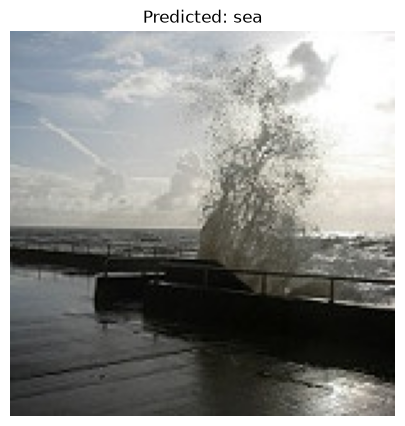

Predicted Class: sea

Confidence Scores:
    Class  Confidence (%)
      sea       98.389999
   street        0.800000
buildings        0.590000
  glacier        0.230000
   forest        0.000000
 mountain        0.000000


In [95]:
# Test prediction on a real unseen image

sample_image_path = PRED_DIR / "17218.jpg"

predicted_class, results = predict_image(
    sample_image_path,
    resnet_finetune,
    eval_transform,
    class_names,
    device
)

In [96]:
print("Device:", device)
print("ResNet model available:", "resnet_finetune" in globals())
print("Training loader available:", "train_loader" in globals())
print("Validation loader available:", "val_loader" in globals())

Device: cuda
ResNet model available: True
Training loader available: True
Validation loader available: True


In [97]:
import torch
import torch.nn as nn
from torchvision.models import resnet18

# Load the saved feature-extraction checkpoint
checkpoint_path = PROJECT_DIR / "models" / "resnet18_feature_extraction.pth"
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

# Create ResNet18 architecture
resnet_best = resnet18(weights=None)
resnet_best.fc = nn.Linear(resnet_best.fc.in_features, len(class_names))

# Load pretrained feature-extraction weights
resnet_best.load_state_dict(checkpoint["model_state_dict"])
resnet_best = resnet_best.to(device)

# Freeze all layers
for param in resnet_best.parameters():
    param.requires_grad = False

# Unfreeze layer4 and final classification layer
for param in resnet_best.layer4.parameters():
    param.requires_grad = True

for param in resnet_best.fc.parameters():
    param.requires_grad = True

# Count trainable parameters
trainable_params = sum(
    param.numel()
    for param in resnet_best.parameters()
    if param.requires_grad
)

print("ResNet18 loaded successfully!")
print("Device:", device)
print("Trainable parameters:", trainable_params)

ResNet18 loaded successfully!
Device: cuda
Trainable parameters: 8396806


In [98]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer: update only trainable parameters
optimizer_best = torch.optim.Adam(
    filter(lambda p: p.requires_grad, resnet_best.parameters()),
    lr=0.0001
)

# Save the best validation accuracy during training
best_val_accuracy = 0.0
best_epoch = 0

# File path for the best checkpoint
best_checkpoint_path = (
    PROJECT_DIR / "models" / "resnet18_finetuned_best.pth"
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate: 0.0001")
print("Best checkpoint path:", best_checkpoint_path)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Best checkpoint path: D:\SS\Jupyter_ML\Intel_Image_Classification\models\resnet18_finetuned_best.pth


In [99]:

EPOCHS_BEST = 4

best_val_accuracy = 0.0
best_epoch = 0

for epoch in range(EPOCHS_BEST):
    # Training
    resnet_best.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_best.zero_grad()
        outputs = resnet_best(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_best.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Validation
    resnet_best.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_best(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    print(
        f"Epoch {epoch + 1}/{EPOCHS_BEST} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%}"
    )

    # Save only when validation accuracy improves
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1

        torch.save(
            {
                "model_state_dict": resnet_best.state_dict(),
                "class_names": class_names,
                "best_epoch": best_epoch,
                "best_val_accuracy": best_val_accuracy,
                "learning_rate": 0.0001,
                "image_size": 224
            },
            best_checkpoint_path
        )

        print(f"  Best checkpoint saved! Val Acc: {best_val_accuracy:.2%}")

print("\nTraining complete!")
print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {best_val_accuracy:.2%}")
print("Checkpoint saved at:", best_checkpoint_path)


Epoch 1/4 | Train Loss: 0.2874 | Train Acc: 90.20% | Val Loss: 0.2254 | Val Acc: 92.52%
  Best checkpoint saved! Val Acc: 92.52%
Epoch 2/4 | Train Loss: 0.1822 | Train Acc: 93.42% | Val Loss: 0.2173 | Val Acc: 92.55%
  Best checkpoint saved! Val Acc: 92.55%
Epoch 3/4 | Train Loss: 0.1362 | Train Acc: 95.28% | Val Loss: 0.2322 | Val Acc: 92.95%
  Best checkpoint saved! Val Acc: 92.95%
Epoch 4/4 | Train Loss: 0.1105 | Train Acc: 95.98% | Val Loss: 0.2467 | Val Acc: 92.91%

Training complete!
Best epoch: 3
Best validation accuracy: 92.95%
Checkpoint saved at: D:\SS\Jupyter_ML\Intel_Image_Classification\models\resnet18_finetuned_best.pth


In [100]:

import torch

checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint exists:", best_checkpoint_path.exists())
print("Best epoch:", checkpoint["best_epoch"])
print(f"Best validation accuracy: {checkpoint['best_val_accuracy']:.2%}")
print("Classes:", checkpoint["class_names"])


Checkpoint exists: True
Best epoch: 3
Best validation accuracy: 92.95%
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [101]:

from sklearn.metrics import accuracy_score, classification_report
from torchvision import datasets
from torch.utils.data import DataLoader
import torch

# Load the test dataset (without augmentation)
test_dataset = datasets.ImageFolder(
    root=str(TEST_DIR),
    transform=eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Load the best checkpoint
checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
    weights_only=False
)

resnet_best.load_state_dict(checkpoint["model_state_dict"])
resnet_best.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = resnet_best(images)
        predictions = outputs.argmax(dim=1).cpu()

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

# Print test results
test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Best checkpoint epoch: {checkpoint['best_epoch']}")
print(f"Best validation accuracy: {checkpoint['best_val_accuracy']:.2%}")
print(f"Test accuracy: {test_accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4
))


Best checkpoint epoch: 3
Best validation accuracy: 92.95%
Test accuracy: 92.13%

Classification Report:
              precision    recall  f1-score   support

   buildings     0.9215    0.9130    0.9172       437
      forest     0.9895    0.9895    0.9895       474
     glacier     0.9346    0.8011    0.8627       553
    mountain     0.8274    0.9314    0.8763       525
         sea     0.9469    0.9784    0.9624       510
      street     0.9281    0.9281    0.9281       501

    accuracy                         0.9213      3000
   macro avg     0.9247    0.9236    0.9227      3000
weighted avg     0.9236    0.9213    0.9209      3000



In [102]:

print("Test images evaluated:", len(all_labels))
print("Predictions generated:", len(all_predictions))
print("Best checkpoint exists:", best_checkpoint_path.exists())


Test images evaluated: 3000
Predictions generated: 3000
Best checkpoint exists: True


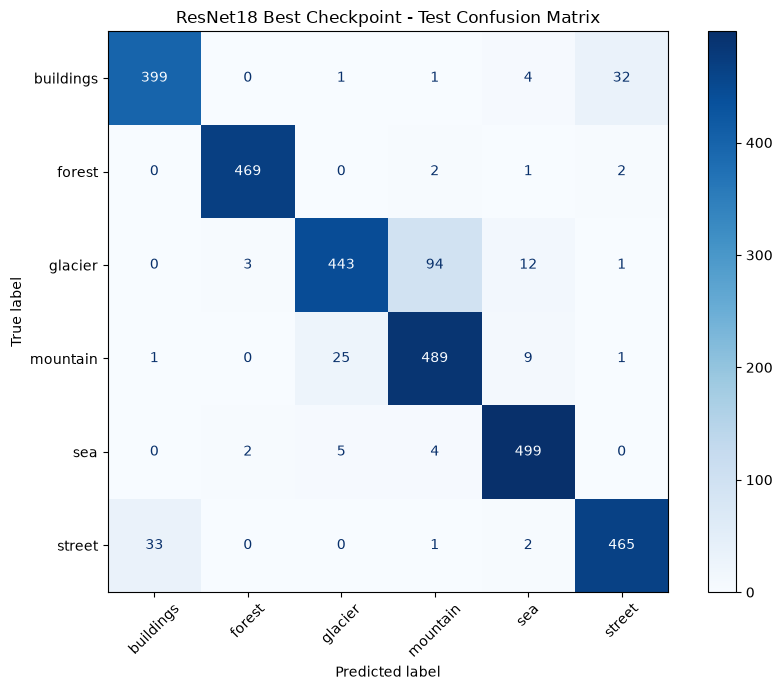

Confusion matrix saved to: D:\SS\Jupyter_ML\Intel_Image_Classification\outputs\confusion_matrices\resnet18_best_test_confusion_matrix.png


In [103]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_best = confusion_matrix(
    all_labels,
    all_predictions
)

# Display the matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
cm_display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("ResNet18 Best Checkpoint - Test Confusion Matrix")
plt.tight_layout()

# Save the figure
cm_path = (
    PROJECT_DIR
    / "outputs"
    / "confusion_matrices"
    / "resnet18_best_test_confusion_matrix.png"
)

cm_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", cm_path)


In [104]:

import pandas as pd
import torch
from pathlib import Path

# Recreate test image paths in the same order as ImageFolder
test_paths = [path for path, label in test_dataset.samples]

# Calculate prediction confidence
resnet_best.eval()
all_confidences = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = resnet_best(images)
        probabilities = torch.softmax(outputs, dim=1)
        confidence = probabilities.max(dim=1).values
        all_confidences.extend(confidence.cpu().tolist())

# Collect misclassified images
misclassified_rows = []

for i, (actual, predicted) in enumerate(zip(all_labels, all_predictions)):
    if actual != predicted:
        misclassified_rows.append({
            "Image": Path(test_paths[i]).name,
            "Image_Path": test_paths[i],
            "Actual_Class": class_names[actual],
            "Predicted_Class": class_names[predicted],
            "Confidence_Percent": round(all_confidences[i] * 100, 2)
        })

misclassified_df = pd.DataFrame(misclassified_rows)

print("Total misclassified images:", len(misclassified_df))
print("\nFirst 10 misclassified images:")
print(misclassified_df.head(10).to_string(index=False))

# Save results
misclassified_path = (
    PROJECT_DIR / "outputs" / "metrics"
    / "resnet18_best_misclassified_images.csv"
)
misclassified_path.parent.mkdir(parents=True, exist_ok=True)
misclassified_df.to_csv(misclassified_path, index=False)

print("\nSaved to:", misclassified_path)


Total misclassified images: 236

First 10 misclassified images:
    Image                                                                                Image_Path Actual_Class Predicted_Class  Confidence_Percent
20074.jpg D:\SS\Jupyter_ML\Intel_Image_Classification\archive\seg_test\seg_test\buildings\20074.jpg    buildings        mountain               69.79
20246.jpg D:\SS\Jupyter_ML\Intel_Image_Classification\archive\seg_test\seg_test\buildings\20246.jpg    buildings          street               99.73
20574.jpg D:\SS\Jupyter_ML\Intel_Image_Classification\archive\seg_test\seg_test\buildings\20574.jpg    buildings          street               65.80
20646.jpg D:\SS\Jupyter_ML\Intel_Image_Classification\archive\seg_test\seg_test\buildings\20646.jpg    buildings          street               53.36
20764.jpg D:\SS\Jupyter_ML\Intel_Image_Classification\archive\seg_test\seg_test\buildings\20764.jpg    buildings          street               73.32
20805.jpg D:\SS\Jupyter_ML\Intel_Image_Cla

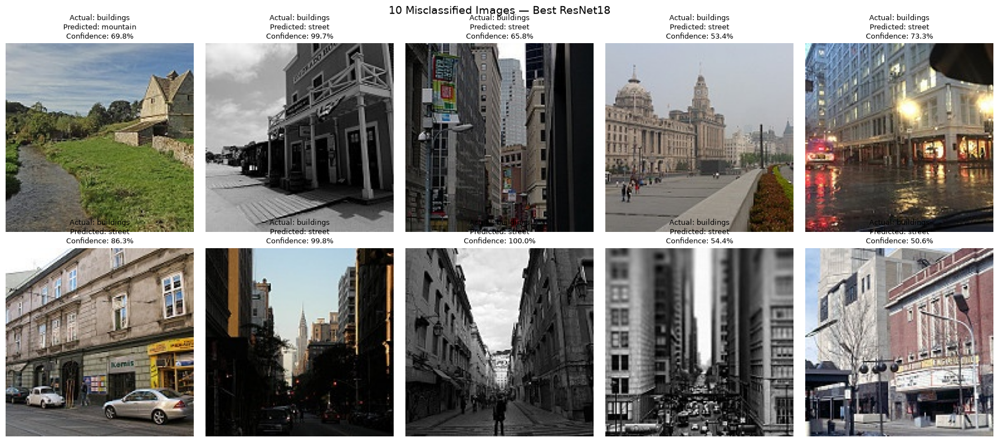

Misclassified image visualization saved to: D:\SS\Jupyter_ML\Intel_Image_Classification\outputs\plots\resnet18_best_10_misclassified.png


In [105]:

import matplotlib.pyplot as plt
from PIL import Image

# Select the first 10 misclassified images
sample_errors = misclassified_df.head(10)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_errors.iterrows()):
    image = Image.open(row["Image_Path"]).convert("RGB")
    ax.imshow(image)

    ax.set_title(
        f"Actual: {row['Actual_Class']}\n"
        f"Predicted: {row['Predicted_Class']}\n"
        f"Confidence: {row['Confidence_Percent']:.1f}%",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle("10 Misclassified Images — Best ResNet18", fontsize=14)
plt.tight_layout()

# Save the figure
error_plot_path = (
    PROJECT_DIR / "outputs" / "plots"
    / "resnet18_best_10_misclassified.png"
)
error_plot_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(error_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Misclassified image visualization saved to:", error_plot_path)


In [106]:

report_path = PROJECT_DIR / "Technical_Report.md"
readme_path = PROJECT_DIR / "README.md"

print("Technical report exists:", report_path.exists())
print("README exists:", readme_path.exists())

if report_path.exists():
    print("\n--- Technical Report: first 30 lines ---")
    print("\n".join(report_path.read_text(encoding="utf-8").splitlines()[:30]))

if readme_path.exists():
    print("\n--- README: first 30 lines ---")
    print("\n".join(readme_path.read_text(encoding="utf-8").splitlines()[:30]))


Technical report exists: True
README exists: True

--- Technical Report: first 30 lines ---
# Intel Image Classification — Technical Report

## 1. Objective
The objective is to classify natural scene images into six classes:
buildings, forest, glacier, mountain, sea, and street.

Two approaches were evaluated:
- SimpleCNN trained from scratch
- ResNet-18 using transfer learning and fine-tuning

## 2. Dataset and Preparation
- Original training images: 14,034
- Training split: 11,227
- Validation split: 2,807
- Separate test images: 3,000
- Unlabeled prediction images: 7,301
- Number of classes: 6
- Corrupted images found during initial checking: 0

Images were resized to 224 x 224 pixels. Training data used
random horizontal flipping, random rotation, and color jitter.
Images were converted to tensors and normalized.

The test dataset was kept separate from training and validation.

## 3. Models

### SimpleCNN
A custom CNN was built using convolutional layers, ReLU activation,
max pool

In [107]:

from datetime import datetime
import shutil

report_path = PROJECT_DIR / "Technical_Report.md"

# Create a backup before editing
backup_path = PROJECT_DIR / "Technical_Report_backup.md"
shutil.copy2(report_path, backup_path)

best_results_section = f"""

## Best ResNet-18 Fine-Tuned Checkpoint

The best checkpoint was selected using validation accuracy.

- Best epoch: {checkpoint['best_epoch']}
- Best validation accuracy: {checkpoint['best_val_accuracy']:.2%}
- Test accuracy: {test_accuracy:.2%}
- Test images evaluated: {len(all_labels)}
- Correct predictions: {sum(a == p for a, p in zip(all_labels, all_predictions))}
- Misclassified images: {len(misclassified_df)}
- Macro precision: 92.47%
- Macro recall: 92.36%
- Macro F1-score: 92.27%
- Weighted F1-score: 92.09%

### Error Analysis

The confusion matrix is saved at:
`outputs/confusion_matrices/resnet18_best_test_confusion_matrix.png`

The misclassified-image list is saved at:
`outputs/metrics/resnet18_best_misclassified_images.csv`

A visualization of ten misclassified test images is saved at:
`outputs/plots/resnet18_best_10_misclassified.png`

The model achieved strong results on forest and sea images. Glacier recall was lower than the other classes, indicating that some actual glacier images were classified as other scene types.

Confidence scores represent the model's predicted probabilities; a high confidence score does not guarantee that a prediction is correct.
"""

with report_path.open("a", encoding="utf-8") as file:
    file.write(best_results_section)

print("Technical report updated:", report_path)
print("Backup created:", backup_path)


Technical report updated: D:\SS\Jupyter_ML\Intel_Image_Classification\Technical_Report.md
Backup created: D:\SS\Jupyter_ML\Intel_Image_Classification\Technical_Report_backup.md


In [108]:

import shutil

readme_path = PROJECT_DIR / "README.md"

# Create a backup before editing
readme_backup_path = PROJECT_DIR / "README_backup.md"
shutil.copy2(readme_path, readme_backup_path)

readme_update = """

## Best ResNet-18 Checkpoint Results

The best fine-tuned checkpoint was selected using validation accuracy.

| Metric | Result |
|---|---:|
| Best epoch | 3 |
| Validation accuracy | 92.95% |
| Test accuracy | 92.13% |
| Macro precision | 92.47% |
| Macro recall | 92.36% |
| Macro F1-score | 92.27% |
| Weighted F1-score | 92.09% |

### Best Model Files

- Checkpoint: `models/resnet18_finetuned_best.pth`
- Confusion matrix: `outputs/confusion_matrices/resnet18_best_test_confusion_matrix.png`
- Misclassified images CSV: `outputs/metrics/resnet18_best_misclassified_images.csv`
- Ten-image error analysis: `outputs/plots/resnet18_best_10_misclassified.png`

### Error Analysis

The model performs particularly well on forest and sea images. Glacier recall is comparatively lower, so some glacier images are classified as other scene categories.

A high prediction confidence does not guarantee a correct prediction.
"""

with readme_path.open("a", encoding="utf-8") as file:
    file.write(readme_update)

print("README updated:", readme_path)
print("README backup created:", readme_backup_path)


README updated: D:\SS\Jupyter_ML\Intel_Image_Classification\README.md
README backup created: D:\SS\Jupyter_ML\Intel_Image_Classification\README_backup.md


In [109]:

import torch
import torch.nn as nn
from torchvision.models import resnet18

# Load the best checkpoint
checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
    weights_only=False
)

# Create the same ResNet18 architecture
best_model = resnet18(weights=None)
best_model.fc = nn.Linear(
    best_model.fc.in_features,
    len(class_names)
)

best_model.load_state_dict(checkpoint["model_state_dict"])
best_model = best_model.to(device)
best_model.eval()

print("Best model loaded successfully!")
print("Best epoch:", checkpoint["best_epoch"])
print(f"Validation accuracy: {checkpoint['best_val_accuracy']:.2%}")
print("Device:", device)


Best model loaded successfully!
Best epoch: 3
Validation accuracy: 92.95%
Device: cuda


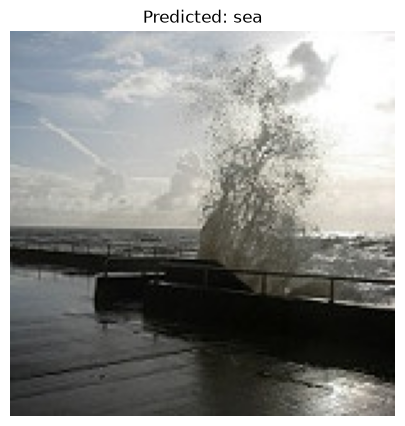

Predicted Class: sea

Confidence Scores:
    Class  Confidence (%)
      sea       96.410004
   street        2.560000
buildings        0.900000
  glacier        0.130000
 mountain        0.010000
   forest        0.000000


In [110]:

# Select one unseen image
sample_image_path = PRED_DIR / "17218.jpg"

# Predict using the best ResNet18 checkpoint
predicted_class, confidence_scores = predict_image(
    image_path=sample_image_path,
    model=best_model,
    transform=eval_transform,
    class_names=class_names,
    device=device
)


In [111]:

invalid_image_path = (
    PROJECT_DIR / "this_image_does_not_exist.jpg"
)

result = predict_image(
    image_path=invalid_image_path,
    model=best_model,
    transform=eval_transform,
    class_names=class_names,
    device=device
)

print("Returned result:", result)


Error: Image file not found: D:\SS\Jupyter_ML\Intel_Image_Classification\this_image_does_not_exist.jpg
Returned result: (None, None)


In [113]:

print("Available augmentation-related variables:")

for name in list(globals().keys()):
    if any(word in name.lower() for word in [
        "augment", "regularization", "ablation", "experiment"
    ]):
        value = globals().get(name)

        if isinstance(value, (dict, list, tuple, pd.DataFrame)):
            print(f"\n{name}:")
            if isinstance(value, pd.DataFrame):
                print(value.head())
            else:
                print(value)


Available augmentation-related variables:

experiment_results:
                      Model  Epochs  Batch Size  Learning Rate  Dropout  \
0      SimpleCNN - Baseline      10          32         0.0010      0.3   
1  SimpleCNN - Experiment 1      10          32         0.0005      0.3   

   Test Accuracy  Test Loss  Final Train Accuracy  Final Validation Accuracy  \
0       0.799333   0.559061                   NaN                        NaN   
1            NaN        NaN              0.710876                   0.752048   

   Final Validation Loss  
0                    NaN  
1               0.658906  

experiment_1_results:
{'Model': 'SimpleCNN - Experiment 1', 'Epochs': 10, 'Batch Size': 32, 'Learning Rate': 0.0005, 'Dropout': 0.3, 'Final Train Accuracy': 0.7108755678275586, 'Final Validation Accuracy': 0.7520484503028144, 'Final Validation Loss': 0.6589059532644234}

regularization_comparison:
                           Experiment  Train Accuracy (%)  \
0        Baseline CNN (Dropo

In [114]:

print("TRAIN TRANSFORM:")
print(train_transform)

print("\nVALIDATION TRANSFORM:")
print(eval_transform)


TRAIN TRANSFORM:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

VALIDATION TRANSFORM:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


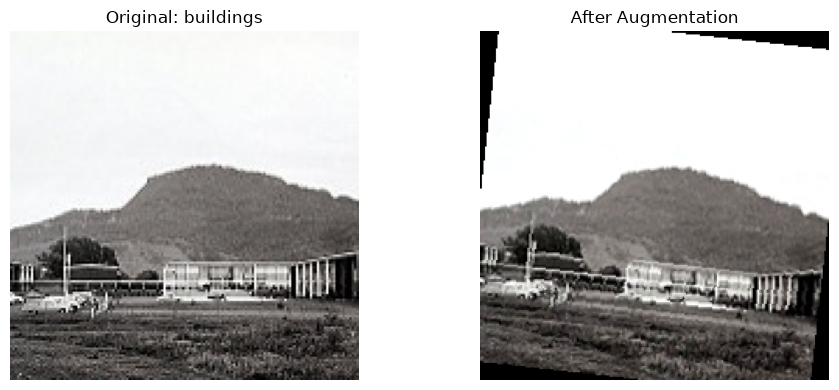

Saved to: D:\SS\Jupyter_ML\Intel_Image_Classification\outputs\plots\augmentation_before_after.png


In [115]:

import matplotlib.pyplot as plt
from PIL import Image
import random

# Select one image from the training dataset
sample_path, sample_label = full_train_dataset.samples[0]
original_image = Image.open(sample_path).convert("RGB")

# Apply training augmentation
augmented_tensor = train_transform(original_image)

# Convert normalized tensor back to displayable image
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

augmented_image = (augmented_tensor.cpu() * std + mean).clamp(0, 1)
augmented_image = augmented_image.permute(1, 2, 0).numpy()

# Display comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(original_image)
axes[0].set_title(f"Original: {class_names[sample_label]}")
axes[0].axis("off")

axes[1].imshow(augmented_image)
axes[1].set_title("After Augmentation")
axes[1].axis("off")

plt.tight_layout()

# Save the comparison
augmentation_path = (
    PROJECT_DIR / "outputs" / "plots"
    / "augmentation_before_after.png"
)
augmentation_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(augmentation_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved to:", augmentation_path)


In [116]:
print("Available model comparison variables:")

for name in [
    "experiment_results",
    "regularization_comparison",
    "resnet_feature_history",
    "finetune_history"
]:
    if name in globals():
        print(f"\n--- {name} ---")
        print(globals()[name])
    else:
        print(f"\n{name}: Not found")

Available model comparison variables:

--- experiment_results ---
                      Model  Epochs  Batch Size  Learning Rate  Dropout  \
0      SimpleCNN - Baseline      10          32         0.0010      0.3   
1  SimpleCNN - Experiment 1      10          32         0.0005      0.3   

   Test Accuracy  Test Loss  Final Train Accuracy  Final Validation Accuracy  \
0       0.799333   0.559061                   NaN                        NaN   
1            NaN        NaN              0.710876                   0.752048   

   Final Validation Loss  
0                    NaN  
1               0.658906  

--- regularization_comparison ---
                           Experiment  Train Accuracy (%)  \
0        Baseline CNN (Dropout = 0.3)             77.3671   
1  Higher Dropout CNN (Dropout = 0.5)             71.1499   

   Validation Accuracy (%)  
0                  80.2993  
1                  75.8105  

resnet_feature_history: Not found

finetune_history: Not found


In [117]:

from pathlib import Path

PROJECT_DIR = Path(r"D:\SS\Jupyter_ML\Intel_Image_Classification")

print("Saved model files:")
for path in (PROJECT_DIR / "models").glob("*.pth"):
    print(path.name)

print("\nSaved metric files:")
for path in (PROJECT_DIR / "outputs" / "metrics").glob("*"):
    print(path.name)


Saved model files:
cnn_baseline.pth
resnet18_feature_extraction.pth
resnet18_finetuned.pth
resnet18_finetuned_best.pth

Saved metric files:
resnet18_best_misclassified_images.csv
resnet18_misclassified_images.csv
resnet18_unseen_predictions.csv


In [118]:

print("Feature Extraction model checkpoint details:")

checkpoint = torch.load(
    PROJECT_DIR / "models" / "resnet18_feature_extraction.pth",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Available keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if not isinstance(value, dict):
            print(f"{key}: {value}")


Feature Extraction model checkpoint details:
Checkpoint type: <class 'dict'>
Available keys: ['model_state_dict', 'class_names', 'class_to_idx', 'image_size', 'validation_accuracy', 'best_validation_accuracy', 'training_method', 'epochs_trained']
class_names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
image_size: 224
validation_accuracy: 0.9006056287851799
best_validation_accuracy: 0.9059494121838262
training_method: ResNet-18 Feature Extraction
epochs_trained: 5


In [119]:

import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score

# Load the saved feature extraction checkpoint
checkpoint = torch.load(
    PROJECT_DIR / "models" / "resnet18_feature_extraction.pth",
    map_location=device,
    weights_only=False
)

# Recreate the ResNet-18 architecture
resnet_feature = models.resnet18(weights=None)
resnet_feature.fc = nn.Linear(512, len(class_names))
resnet_feature.load_state_dict(checkpoint["model_state_dict"])
resnet_feature = resnet_feature.to(device)
resnet_feature.eval()

# Evaluate on the test dataset
feature_true = []
feature_pred = []
feature_loss = 0.0
criterion_eval = nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_feature(images)
        loss = criterion_eval(outputs, labels)

        feature_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)

        feature_true.extend(labels.cpu().tolist())
        feature_pred.extend(predictions.cpu().tolist())

feature_test_accuracy = accuracy_score(feature_true, feature_pred)
feature_test_loss = feature_loss / len(test_loader.dataset)

print(f"Feature Extraction Test Accuracy: {feature_test_accuracy * 100:.2f}%")
print(f"Feature Extraction Test Loss: {feature_test_loss:.4f}")


Feature Extraction Test Accuracy: 90.00%
Feature Extraction Test Loss: 0.2769


In [120]:

resnet_best.eval()

best_test_loss = 0.0
criterion_eval = nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_best(images)
        loss = criterion_eval(outputs, labels)

        best_test_loss += loss.item() * labels.size(0)

best_test_loss /= len(test_loader.dataset)

print(f"Best Fine-tuned ResNet-18 Test Loss: {best_test_loss:.4f}")


Best Fine-tuned ResNet-18 Test Loss: 0.2288


In [121]:

comparison_section = """
## Final Model Comparison

| Model | Best Validation Accuracy | Test Accuracy | Test Loss |
|---|---:|---:|---:|
| SimpleCNN Baseline | 80.30% | 79.93% | 0.5591 |
| ResNet-18 Feature Extraction | 90.59% | 90.00% | 0.2769 |
| ResNet-18 Fine-Tuned (Best Checkpoint) | 92.95% | 92.13% | 0.2288 |

### Conclusion
The fine-tuned ResNet-18 achieved the best test accuracy (92.13%)
and the lowest test loss (0.2288) among the three evaluated models.
The SimpleCNN baseline achieved 79.93% test accuracy.
The fine-tuned model improved test accuracy by approximately
12.20 percentage points over the baseline.

The best fine-tuned checkpoint was selected using validation
performance. The test set was used for final evaluation.
"""

for filename in ["README.md", "Technical_Report.md"]:
    file_path = PROJECT_DIR / filename

    if file_path.exists():
        content = file_path.read_text(encoding="utf-8")

        if "## Final Model Comparison" not in content:
            with file_path.open("a", encoding="utf-8") as f:
                f.write("\n\n" + comparison_section)

            print(f"Updated: {filename}")
        else:
            print(f"Comparison section already exists: {filename}")
    else:
        print(f"File not found: {filename}")


Updated: README.md
Updated: Technical_Report.md


In [123]:

from pathlib import Path

readme_path = PROJECT_DIR / "README.md"

environment_section = """
## Environment and Reproducibility

### Software Versions
- Python: 3.14.5
- PyTorch: 2.14.1+cu130
- Torchvision: 0.29.1+cu130
- NumPy: 2.5.2
- Pandas: 3.0.5
- Scikit-learn: 1.9.1
- Matplotlib: 3.11.1

### Hardware
- GPU: NVIDIA GeForce RTX 3050 A Laptop GPU
- CUDA available: Yes

### Reproducibility Notes
- Use the same dataset structure and preprocessing pipeline.
- Use the saved best model checkpoint for final predictions.
- Select models using validation performance and reserve the test set for final evaluation.
"""

if readme_path.exists():
    readme_content = readme_path.read_text(encoding="utf-8")

    if "## Environment and Reproducibility" not in readme_content:
        with readme_path.open("a", encoding="utf-8") as file:
            file.write("\n\n" + environment_section)
        print("Environment details added to README.md")
    else:
        print("Environment section already exists in README.md")
else:
    print("README.md not found:", readme_path)


Environment details added to README.md


In [124]:

import random
import numpy as np
import torch

print("Random seed settings check:")

print("Python random state:", random.getstate()[1][0])
print("NumPy random state:", np.random.get_state()[1][0])
print("PyTorch initial seed:", torch.initial_seed())

print("\nSaved best checkpoint metadata:")

checkpoint_path = PROJECT_DIR / "models" / "resnet18_finetuned_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

for key, value in checkpoint.items():
    if key != "model_state_dict":
        print(f"{key}: {value}")


Random seed settings check:
Python random state: 2468570525
NumPy random state: 2147483648
PyTorch initial seed: 1914293231498400

Saved best checkpoint metadata:
class_names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
best_epoch: 3
best_val_accuracy: 0.9294620591378696
learning_rate: 0.0001
image_size: 224


In [125]:

import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)
print("CUDA available:", torch.cuda.is_available())


Random seed set to: 42
CUDA available: True


In [126]:

readme_path = PROJECT_DIR / "README.md"

seed_section = """
### Random Seed
- Seed value: 42
- Python random, NumPy, and PyTorch seeds are set to 42.
- CUDA random seed is also set when CUDA is available.
- For reproducible training, set these seeds before data splitting and model training.
"""

content = readme_path.read_text(encoding="utf-8")

if "### Random Seed" not in content:
    with readme_path.open("a", encoding="utf-8") as file:
        file.write("\n" + seed_section)
    print("Random seed details added to README.md")
else:
    print("Random seed details already exist in README.md")


Random seed details added to README.md


In [128]:
import sys
print(sys.executable)

C:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\python.exe
